# Swin UNETR for Glioma Segmentation

## Purpose

This notebook trains a **Swin UNETR** under exactly the same conditions as the
**3D U-Net baseline**, so that the two architectures can be compared fairly.

### Model size

`FEATURE_SIZE = 12` (the smallest Swin UNETR, about 4 M parameters; the exact number is
printed by the model cell) instead of 24 (15.7 M), to keep the capacity close to the CNNs
(3D U-Net baseline ≈ 1.4 M, MONAI U-Net + MAE ≈ 1.2 M) and compare architectures rather
than model sizes.

### Identical to the 3D U-Net baseline

| Element | Value |
|---|---|
| Patients | `segmentation_manifest.csv` (1180: train 826 / validation 177 / test 177) |
| Cross-validation | same 5 folds on the 1003 development patients (`5fold_manifest.csv`), test kept aside |
| File paths | read directly from the manifest |
| Pre-processing | percentile clipping 0.5–99.5 + z-score on non-zero voxels, labels {0,1,2,4} → {0,1,2,3} |
| Patch sampling | 64 × 64 × 64, 2 patches/patient/epoch, 75% centered on tumor |
| Augmentation | random flips, 90° rotations, intensity scale/shift |
| Loss | 0.5 Cross-Entropy + 0.5 soft Dice (foreground) |
| Metrics | Dice and IoU (mean over the 3 foreground classes) |
| Model selection | lowest validation loss, early stopping patience 10, max 50 epochs |
| Optimizer | AdamW, lr 1e-4, weight decay 1e-5, batch size 2, mixed precision |

### What changes (and why)

| Element | 3D U-Net | Swin UNETR |
|---|---|---|
| Encoder | convolutions | Swin Transformer (shifted-window self-attention) |
| Decoder | CNN + skip connections | CNN + skip connections (residual blocks) |
| LR schedule | constant | linear warm-up (5 epochs) + cosine decay |
| Gradient clipping | none | max norm 1.0 |
| Validation inference | whole volume in one pass | sliding window (64³, overlap 0.5, Gaussian blending) |

Transformers trained from scratch are less stable than CNNs: warm-up and gradient
clipping are the standard remedies. Swin UNETR requires every spatial dimension to be
divisible by 32: the full volume (240 × 240 × 155) is not, so validation uses
sliding-window inference. Loss and metrics are still computed on the **full volume**,
exactly as in the baseline.

### Additional evaluation (both models)

The last section computes, per patient, Dice, IoU, HD and HD95 for the **whole tumor**
(objective 1a) and for the **three sub-regions** (objective 1b), as required by the
assignment. The function takes a generic prediction function, so the same cell can be
copied into the 3D U-Net notebook to evaluate both models identically.

### Speed and session management (no effect on the results)

| Feature | What it does |
|---|---|
| Preprocessed cache | Each patient is preprocessed **once** with the same `load_patient_volumes` and stored (cropped to the non-zero region) on the scratch disk. Patches and full volumes are rebuilt **exactly** as in the original pipeline (same random centers, same coordinates); an equivalence check verifies it at every run. Only difference: float16 storage (rounding ≈ 5·10⁻⁴). |
| Validation on 2 GPUs | Training runs on one GPU; validation and final evaluation predict the two volumes of a batch in parallel, one per GPU (`VALIDATION_GPUS = 2`), with one model copy per GPU refreshed once per validation and worker threads created once. Same predictions as on one GPU, epoch ≈ 16 min instead of 28. `nn.DataParallel` is not used (RAM leak). |
| Resumable training | A `last` checkpoint (model, optimizer, scheduler, scaler, history, early-stopping counters, random states) is saved after every epoch. With `RESUME_FROM` a new session continues where the previous one stopped. |
| Session time budget | Training stops cleanly before the 12 h Kaggle limit (`MAX_SESSION_HOURS`). |
| `DEBUG_MODE` | Quick end-to-end check on a few patients and 2 epochs, in a separate output folder. |
| Memory safety | The model runs on one GPU (`USE_DATA_PARALLEL = False`: `nn.DataParallel` made the RAM of the notebook process grow by ~10 GB per epoch). Freed memory is returned to the system periodically, RAM is logged (`results/memory_log_*.csv`) and printed at every epoch, and a memory budget ends the session cleanly instead of letting the kernel die. |

Sliding-window overlap is unchanged (0.5).

**Kaggle settings:** GPU T4 × 2, Internet ON (to install MONAI).


## 1. Setup

Set `DEBUG_MODE`, `FOLDS_TO_RUN`, `RESUME_FROM` and the manifest paths in the configuration cell.

In [1]:
# ================================================================
# CELL 1 - IMPORT LIBRARIES
# ================================================================

import os
import gc
import sys
import json
import math
import time
import random
import warnings
import subprocess
import importlib.util
from pathlib import Path
from collections import Counter
import shutil
import multiprocessing as mp
import threading
import ctypes

NOTEBOOK_START_TIME = time.time()

# CPU memory allocator (glibc): at most 2 allocation arenas, plus a function that
# gives the freed memory back to the system. Only memory management: no effect on results.
try:
    _libc = ctypes.CDLL("libc.so.6")
    _libc.mallopt(-8, 2)   # M_ARENA_MAX = 2
except (OSError, AttributeError):
    _libc = None


def release_cpu_memory():
    """Python garbage collection + return freed heap memory to the OS."""
    gc.collect()
    if _libc is not None:
        _libc.malloc_trim(0)


# Set by the memory monitor when the RAM is almost full: the running epoch is
# interrupted cleanly instead of letting the kernel die.
MEMORY_EMERGENCY = threading.Event()

# MONAI provides Swin UNETR and sliding-window inference (einops is required by Swin UNETR)
for module, package in {"monai": "monai", "einops": "einops"}.items():
    if importlib.util.find_spec(module) is None:
        subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", package])

import numpy as np
import pandas as pd
import nibabel as nib

import matplotlib.pyplot as plt
from matplotlib.colors import ListedColormap

from sklearn.model_selection import StratifiedKFold, KFold
from scipy.ndimage import distance_transform_edt, binary_erosion

import torch
import torch.nn as nn
import torch.nn.functional as F

from torch.utils.data import Dataset, DataLoader

import monai
from monai.networks.nets import SwinUNETR
from monai.inferers import sliding_window_inference

warnings.filterwarnings("ignore")

print("Libraries imported successfully.")
print("PyTorch:", torch.__version__, "| MONAI:", monai.__version__)

# ================================================================
# CELL 2 - GENERAL CONFIGURATION
# ================================================================

# -------------------------------
# Dataset paths (same as the 3D U-Net baseline)
# -------------------------------

IMAGES_DIR = Path(
    "/kaggle/input/datasets/laurapitton/training-images/Training_images"
)

# MODIFICA questi percorsi con quelli effettivi dei manifest
MANIFEST_PATH = Path(
    "/kaggle/input/datasets/liviapantarotto/segmentation-manifest/segmentation_manifest.csv"
)

# Fold assignment used by the 3D U-Net baseline. If found, the folds are read from here;
# otherwise they are regenerated with the same code and seed as the baseline.
SHARED_FOLD_MANIFEST_PATH = Path(
    "/kaggle/input/datasets/liviapantarotto/5foldmanifest/5fold_manifest.csv"
)

# -------------------------------
# Run mode
# -------------------------------
# DEBUG_MODE = True  -> quick end-to-end check (few patients, 2 epochs,
#                       separate output folder): use it after every change
# DEBUG_MODE = False -> real training

DEBUG_MODE = False

DEBUG_TRAIN_PATIENTS = 16
DEBUG_VAL_PATIENTS = 4
DEBUG_EPOCHS = 2

# -------------------------------
# Output directory
# -------------------------------

OUTPUT_DIR = Path(
    "/kaggle/working/glioma_swin_unetr_fs12" + ("_debug" if DEBUG_MODE else "")
)

OUTPUT_DIR.mkdir(
    parents=True,
    exist_ok=True
)

CHECKPOINT_DIR = OUTPUT_DIR / "checkpoints"
CHECKPOINT_DIR.mkdir(exist_ok=True)

RESULTS_DIR = OUTPUT_DIR / "results"
RESULTS_DIR.mkdir(exist_ok=True)

# -------------------------------
# Resume from a previous session (optional)
# -------------------------------
# Output folder of a previous version of THIS notebook, added as input
# (Add Input -> Your Work -> this notebook), e.g.
#   Path("/kaggle/input/<...>/glioma_swin_unetr_fs12")
# None = start from scratch.

# Trova automaticamente la cartella della run precedente tra gli input
RESUME_FROM = next(
    (p for pattern in ["*/glioma_swin_unetr_fs12", "*/*/glioma_swin_unetr_fs12",
                       "*/*/*/glioma_swin_unetr_fs12", "*/*/*/*/glioma_swin_unetr_fs12"]
     for p in Path("/kaggle/input").glob(pattern)),
    None
)
print("RESUME_FROM:", RESUME_FROM)
assert RESUME_FROM is not None, "Cartella glioma_swin_unetr_fs12 non trovata negli input"

if RESUME_FROM is not None:

    RESUME_FROM = Path(RESUME_FROM)

    if not RESUME_FROM.exists():
        raise FileNotFoundError(f"RESUME_FROM not found: {RESUME_FROM}")

    for subfolder in ["checkpoints", "results"]:
        if (RESUME_FROM / subfolder).exists():
            shutil.copytree(
                RESUME_FROM / subfolder,
                OUTPUT_DIR / subfolder,
                dirs_exist_ok=True
            )

    print("Previous checkpoints and results copied from:", RESUME_FROM)

    for path in sorted(CHECKPOINT_DIR.glob("*.pth")):
        print("  ", path.name)

# -------------------------------
# Reproducibility
# -------------------------------

SEED = 42

def set_seed(seed=42):

    random.seed(seed)
    np.random.seed(seed)

    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)

    os.environ["PYTHONHASHSEED"] = str(seed)

set_seed(SEED)

# -------------------------------
# Device configuration
# -------------------------------

DEVICE = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

print("Device:", DEVICE)

if torch.cuda.is_available():

    print("Number of GPUs:", torch.cuda.device_count())

    for i in range(torch.cuda.device_count()):
        print(
            f"GPU {i}:",
            torch.cuda.get_device_name(i)
        )
else:
    print("WARNING: no GPU. Enable 'GPU T4 x2' in the Kaggle notebook settings.")

# -------------------------------
# Training parameters (identical to the 3D U-Net baseline)
# -------------------------------

N_FOLDS = 5

# Folds trained in this session (e.g. [0] to compare models on one fold first)
FOLDS_TO_RUN = [0]

PATCH_SIZE = (64, 64, 64)

BATCH_SIZE = 2

# Only affect data-loading speed / memory, not the results
NUM_WORKERS = 4        # training patches (small)
VAL_NUM_WORKERS = 2    # validation full volumes (~0.3 GB per batch)

# RAM / shared-memory log interval (seconds)
MEMORY_LOG_SECONDS = 120

# Multi-GPU with nn.DataParallel. The total batch is the same (BATCH_SIZE), so this
# only changes speed and memory, not the results.
# False = 1 GPU: nn.DataParallel made the RAM of the notebook process grow by ~10 GB
# per epoch (kernel died at epoch 3 and 5).
USE_DATA_PARALLEL = False

# Validation and final evaluation on several GPUs WITHOUT nn.DataParallel: the volumes
# of a batch are predicted in parallel, one per GPU (same predictions, ~1.8x faster).
# Training always uses one GPU. 1 = everything on one GPU (as in v5).
VALIDATION_GPUS = 2

# Training stops cleanly (checkpoints already saved) before an epoch that would
# push the RAM above this percentage; above EMERGENCY_RAM_PERCENT the running
# epoch is interrupted. In both cases the session ends normally and can be resumed.
MAX_RAM_PERCENT = 85
EMERGENCY_RAM_PERCENT = 93

# Give freed CPU memory back to the system every N batches
TRIM_EVERY_TRAIN_BATCHES = 100
TRIM_EVERY_VAL_BATCHES = 10

MAX_EPOCHS = 50

LEARNING_RATE = 1e-4

WEIGHT_DECAY = 1e-5

PATIENCE = 10

MODALITIES = [
    "FLAIR",
    "T1",
    "T1CE",
    "T2"
]

NUM_INPUT_CHANNELS = 4
NUM_CLASSES = 4

# -------------------------------
# Swin UNETR parameters
# -------------------------------

# Embedding size of the first stage; must be divisible by 12.
# 12 = smallest model (closest in size to the CNN baselines, ~4 M parameters),
# 24 = "small" (15.7 M), 48 = original paper (62 M).
FEATURE_SIZE = 12

DEPTHS = (2, 2, 2, 2)          # Swin Transformer blocks per stage
NUM_HEADS = (3, 6, 12, 24)     # attention heads per stage
DROPOUT_PATH_RATE = 0.0        # stochastic depth
USE_CHECKPOINT = False         # gradient checkpointing: set True for 96³ / 128³ patches

# Optimization (transformer-specific)
WARMUP_EPOCHS = 5
GRAD_CLIP_NORM = 1.0

# Sliding-window inference on full volumes
SW_OVERLAP = 0.5
SW_BATCH_SIZE = 8
SW_MODE = "gaussian"

# -------------------------------
# Speed and session management (no effect on the results)
# -------------------------------

# Scratch disk (not saved with the notebook output): rebuilt at every session
CACHE_DIR = Path("/kaggle/tmp/glioma_cache")

# float16 halves the disk space (rounding ~5e-4); float32 = bit-identical
CACHE_DTYPE = np.float16

CACHE_PROCESSES = 4

# Training stops cleanly before starting an epoch that would exceed this budget
MAX_SESSION_HOURS = 10.5

# Final evaluation (HD/HD95 on every validation patient) is skipped,
# and can be run in the next session, if the session is older than this
EVALUATION_DEADLINE_HOURS = 11.0

# Swin UNETR downsamples 5 times -> every patch side must be divisible by 32
assert all(size % 32 == 0 for size in PATCH_SIZE), (
    "Swin UNETR requires PATCH_SIZE divisible by 32 (e.g. 64, 96, 128)."
)



def use_multi_gpu():
    return USE_DATA_PARALLEL and torch.cuda.is_available() and torch.cuda.device_count() > 1


print("GPUs used by the model:", 2 if use_multi_gpu() else 1,
      "(nn.DataParallel)" if use_multi_gpu() else "")

if DEBUG_MODE:

    MAX_EPOCHS = DEBUG_EPOCHS

    print(
        f"\nDEBUG MODE: {DEBUG_TRAIN_PATIENTS} training / {DEBUG_VAL_PATIENTS} "
        f"validation patients per fold, {MAX_EPOCHS} epochs, output in {OUTPUT_DIR}"
    )

print("\nConfiguration completed.")


I0000 00:00:1794915484.056334      23 cudart_stub.cc:31] Could not find cuda drivers on your machine, GPU will not be used.
Failed to load nvjpeg2k library! Please install nvJPEG2000 (see https://docs.nvidia.com/cuda/nvjpeg2000/userguide.html#installing-nvjpeg2000).
Note: If using nvImageCodec's Python distribution, it is enough to install the nvJPEG2000 wheel: e.g. `python3 -m pip install nvidia-nvjpeg2k-cu13`
[ERROR] [nvjpeg2k_ext] Failed to load nvJPEG2000 library or retrieve version. Decoders and encoders will not be registered.
Failed to load nvtiff library! Please install nvTIFF (see https://docs.nvidia.com/cuda/nvtiff/userguide.html#installing-nvtiff).
Note: If using nvImageCodec's Python distribution, it is enough to install the nvTIFF wheel: e.g. `python3 -m pip install nvidia-nvtiff-cu13`
[ERROR] [nvtiff_ext] Failed to load nvTIFF library or retrieve version. Decoders and encoders will not be registered.


Libraries imported successfully.
PyTorch: 2.11.0+cu130 | MONAI: 1.6.1
RESUME_FROM: /kaggle/input/notebooks/andreatoselli03/braint-swinunetr/glioma_swin_unetr_fs12
Previous checkpoints and results copied from: /kaggle/input/notebooks/andreatoselli03/braint-swinunetr/glioma_swin_unetr_fs12
   swin_unetr_fold0_best.pth
   swin_unetr_fold0_last.pth
Device: cuda
Number of GPUs: 2
GPU 0: Tesla T4
GPU 1: Tesla T4
GPUs used by the model: 1 

Configuration completed.


## 2. Data: manifest, split, pre-processing, augmentation

All cells in this section are **identical to the 3D U-Net baseline**, except the last one (preprocessed cache), which only changes how fast the same data are read.

In [2]:
# ================================================================
# CELL 3 - CHECK DATASET PATHS
# ================================================================

print("Checking dataset paths...\n")

print(
    "MRI directory:",
    IMAGES_DIR.exists()
)

print(
    "Manifest file:",
    MANIFEST_PATH.exists()
)

if not IMAGES_DIR.exists():
    raise FileNotFoundError(
        f"MRI directory not found: {IMAGES_DIR}"
    )

if not MANIFEST_PATH.exists():
    raise FileNotFoundError(
        f"Manifest not found: {MANIFEST_PATH}\n"
        "Please update MANIFEST_PATH in Cell 2."
    )

print("\nAll required paths are available.")

# ================================================================
# CELL 4 - LOAD SEGMENTATION MANIFEST
# ================================================================

manifest = pd.read_csv(MANIFEST_PATH)

print("Manifest loaded successfully.")
print("Number of patients:", len(manifest))

print("\nAvailable columns:")
print(manifest.columns.tolist())

display(manifest.head())

# ================================================================
# CELL 5 - VALIDATE MANIFEST
# ================================================================

REQUIRED_COLUMNS = [
    "patient_folder",
    "FLAIR_path",
    "T1_path",
    "T1CE_path",
    "T2_path",
    "MASK_path",
    "split",
    "Cohort ID"
]

# Check required columns
missing_columns = [
    col for col in REQUIRED_COLUMNS
    if col not in manifest.columns
]

if missing_columns:
    raise ValueError(
        f"Missing columns in manifest: {missing_columns}"
    )

# Check split distribution
print("Original split distribution:")
print(manifest["split"].value_counts(dropna=False))

print("\nPatients per cohort:")
print(manifest["Cohort ID"].value_counts(dropna=False))

# Check duplicate patients
print(
    "\nDuplicate patient folders:",
    manifest["patient_folder"].duplicated().sum()
)

# Check missing values in essential columns
print("\nMissing values:")
display(
    manifest[REQUIRED_COLUMNS].isna().sum()
)

# Check expected patient counts
assert len(manifest) == 1180, (
    f"Expected 1180 patients, found {len(manifest)}"
)

assert manifest["patient_folder"].is_unique, (
    "Duplicate patient folders detected."
)

print("\nManifest validation completed.")

Checking dataset paths...

MRI directory: True
Manifest file: True

All required paths are available.
Manifest loaded successfully.
Number of patients: 1180

Available columns:
['patient_key', 'patient_folder', 'Cohort ID', 'split', 'is_labeled', 'is_unlabeled', 'use_for_mae', 'use_for_segmentation', 'FLAIR', 'T1', 'T1CE', 'T2', 'ALL_MODALITIES_PRESENT', 'FLAIR_path', 'T1_path', 'T1CE_path', 'T2_path', 'MASK', 'MASK_path', 'MRI_COMBINATION']


,patient_key,patient_folder,Cohort ID,split,is_labeled,is_unlabeled,use_for_mae,use_for_segmentation,FLAIR,T1,T1CE,T2,ALL_MODALITIES_PRESENT,FLAIR_path,T1_path,T1CE_path,T2_path,MASK,MASK_path,MRI_COMBINATION
0,1,1,1,validation,True,False,False,True,True,True,True,True,True,/kaggle/input/datasets/laurapitton/training-im...,/kaggle/input/datasets/laurapitton/training-im...,/kaggle/input/datasets/laurapitton/training-im...,/kaggle/input/datasets/laurapitton/training-im...,True,/kaggle/input/datasets/laurapitton/training-im...,FLAIR + T1 + T1CE + T2
1,10,10,2,train,True,False,True,True,True,True,True,True,True,/kaggle/input/datasets/laurapitton/training-im...,/kaggle/input/datasets/laurapitton/training-im...,/kaggle/input/datasets/laurapitton/training-im...,/kaggle/input/datasets/laurapitton/training-im...,True,/kaggle/input/datasets/laurapitton/training-im...,FLAIR + T1 + T1CE + T2
2,1000,1000,8,test,True,False,False,True,True,True,True,True,True,/kaggle/input/datasets/laurapitton/training-im...,/kaggle/input/datasets/laurapitton/training-im...,/kaggle/input/datasets/laurapitton/training-im...,/kaggle/input/datasets/laurapitton/training-im...,True,/kaggle/input/datasets/laurapitton/training-im...,FLAIR + T1 + T1CE + T2
3,1001,1001,8,train,True,False,True,True,True,True,True,True,True,/kaggle/input/datasets/laurapitton/training-im...,/kaggle/input/datasets/laurapitton/training-im...,/kaggle/input/datasets/laurapitton/training-im...,/kaggle/input/datasets/laurapitton/training-im...,True,/kaggle/input/datasets/laurapitton/training-im...,FLAIR + T1 + T1CE + T2
4,1002,1002,8,train,True,False,True,True,True,True,True,True,True,/kaggle/input/datasets/laurapitton/training-im...,/kaggle/input/datasets/laurapitton/training-im...,/kaggle/input/datasets/laurapitton/training-im...,/kaggle/input/datasets/laurapitton/training-im...,True,/kaggle/input/datasets/laurapitton/training-im...,FLAIR + T1 + T1CE + T2


Original split distribution:
split
train         826
validation    177
test          177
Name: count, dtype: int64

Patients per cohort:
Cohort ID
8    378
4    348
7    233
5     94
6     65
2     33
3     25
1      4
Name: count, dtype: int64

Duplicate patient folders: 0

Missing values:


patient_folder    0
FLAIR_path        0
T1_path           0
T1CE_path         0
T2_path           0
MASK_path         0
split             0
Cohort ID         0
dtype: int64


Manifest validation completed.


In [3]:
# ================================================================
# CELL 6 - DEVELOPMENT AND TEST SET
# ================================================================

development_df = manifest[
    manifest["split"].isin(["train", "validation"])
].copy().reset_index(drop=True)

test_df = manifest[
    manifest["split"] == "test"
].copy().reset_index(drop=True)

print("Development patients:", len(development_df))
print("Independent test patients:", len(test_df))

assert len(development_df) == 1003
assert len(test_df) == 177

# Verify patient-level separation
development_ids = set(
    development_df["patient_folder"].astype(str)
)

test_ids = set(
    test_df["patient_folder"].astype(str)
)

assert development_ids.isdisjoint(test_ids), (
    "Data leakage detected between development and test sets!"
)

print("\nNo patient overlap between development and test.")

# ================================================================
# CELL 7 - VERIFY MRI AND MASK FILES
# ================================================================

PATH_COLUMNS = [
    "FLAIR_path",
    "T1_path",
    "T1CE_path",
    "T2_path",
    "MASK_path"
]

missing_files = []

for _, row in manifest.iterrows():

    patient = row["patient_folder"]

    for column in PATH_COLUMNS:

        path = row[column]

        if not isinstance(path, str) or not Path(path).is_file():

            missing_files.append({
                "patient": patient,
                "column": column,
                "path": path
            })

missing_files_df = pd.DataFrame(missing_files)

print("Missing files:", len(missing_files_df))

if len(missing_files_df) > 0:

    display(missing_files_df.head(20))

    raise FileNotFoundError(
        "Some MRI or mask files are missing. "
        "Check the manifest paths before training."
    )

print("\nAll MRI volumes and masks are accessible.")


Development patients: 1003
Independent test patients: 177

No patient overlap between development and test.
Missing files: 0

All MRI volumes and masks are accessible.


In [4]:
# ================================================================
# CELL 8 - 5-FOLD CROSS-VALIDATION SPLITS (same folds as the 3D U-Net)
# ================================================================

# Work only with the development set
cv_df = development_df.copy().reset_index(drop=True)

if SHARED_FOLD_MANIFEST_PATH.exists():

    shared_folds = pd.read_csv(SHARED_FOLD_MANIFEST_PATH)[["patient_folder", "fold"]]

    cv_df = cv_df.merge(
        shared_folds,
        on="patient_folder",
        how="left"
    )

    assert cv_df["fold"].notna().all(), (
        "Some development patients have no fold in the shared fold manifest."
    )

    cv_df["fold"] = cv_df["fold"].astype(int)

    print("Folds loaded from the shared fold manifest (identical to the 3D U-Net baseline).")

else:

    print(
        "Shared fold manifest not found: folds regenerated with the same code "
        "and seed as the 3D U-Net baseline."
    )

    stratification_labels = (
        cv_df["Cohort ID"]
        .fillna("Unknown")
        .astype(str)
    )

    if stratification_labels.value_counts().min() >= N_FOLDS:

        print("Using StratifiedKFold by Cohort ID.")

        cv = StratifiedKFold(
            n_splits=N_FOLDS,
            shuffle=True,
            random_state=SEED
        )

        split_iterator = cv.split(
            cv_df,
            stratification_labels
        )

    else:

        print("At least one cohort has fewer than 5 patients: using standard KFold.")

        cv = KFold(
            n_splits=N_FOLDS,
            shuffle=True,
            random_state=SEED
        )

        split_iterator = cv.split(cv_df)

    cv_df["fold"] = -1

    for fold, (_, val_indices) in enumerate(split_iterator):
        cv_df.loc[val_indices, "fold"] = fold

# Verify assignments
assert (cv_df["fold"] >= 0).all()
assert cv_df["patient_folder"].is_unique

# Save fold assignments used by this notebook
FOLD_MANIFEST_PATH = OUTPUT_DIR / "5fold_manifest.csv"

cv_df.to_csv(
    FOLD_MANIFEST_PATH,
    index=False
)

print("\nPatients assigned to each fold:")
print(cv_df["fold"].value_counts().sort_index())

# ================================================================
# CELL 9 - VERIFY FOLD DISTRIBUTION
# ================================================================

print("\nCohort distribution per fold:\n")

display(
    pd.crosstab(
        cv_df["fold"],
        cv_df["Cohort ID"]
    )
)

# ================================================================
# CELL 10 - VERIFY CROSS-VALIDATION INTEGRITY
# ================================================================

all_validation_ids = []

for fold in range(N_FOLDS):

    val_fold = cv_df[cv_df["fold"] == fold]
    train_fold = cv_df[cv_df["fold"] != fold]

    train_ids = set(train_fold["patient_folder"].astype(str))
    val_ids = set(val_fold["patient_folder"].astype(str))

    assert train_ids.isdisjoint(val_ids), (
        f"Leakage detected in fold {fold}"
    )

    all_validation_ids.extend(val_ids)

    print(
        f"Fold {fold}: "
        f"Train = {len(train_ids)}, "
        f"Validation = {len(val_ids)}"
    )

# Every development patient must be validation exactly once
assert len(all_validation_ids) == len(set(all_validation_ids))
assert set(all_validation_ids) == set(cv_df["patient_folder"].astype(str))

# Test set must remain excluded
assert set(cv_df["patient_folder"].astype(str)).isdisjoint(
    set(test_df["patient_folder"].astype(str))
)

print("\nAll cross-validation integrity checks passed.")


Folds loaded from the shared fold manifest (identical to the 3D U-Net baseline).

Patients assigned to each fold:
fold
0    201
1    201
2    201
3    200
4    200
Name: count, dtype: int64

Cohort distribution per fold:



Cohort ID,1,2,3,4,5,6,7,8
fold,,,,,,,,
0,1,8,5,61,15,8,39,64
1,1,7,2,62,26,9,29,65
2,1,6,4,56,15,16,32,71
3,1,1,3,59,7,16,52,61
4,0,6,7,58,17,6,46,60


Fold 0: Train = 802, Validation = 201
Fold 1: Train = 802, Validation = 201
Fold 2: Train = 802, Validation = 201
Fold 3: Train = 803, Validation = 200
Fold 4: Train = 803, Validation = 200

All cross-validation integrity checks passed.


In [5]:
# ================================================================
# CELL 11 - LABEL MAPPING AND PREPROCESSING CONFIGURATION
# ================================================================

# Original dataset labels -> consecutive training labels
LABEL_MAPPING = {
    0: 0,  # Background
    1: 1,  # Necrotic core
    2: 2,  # FLAIR signal hyperintensity
    4: 3   # Enhancing tumor
}

CLASS_NAMES = {
    0: "Background",
    1: "Necrotic core",
    2: "FLAIR signal hyperintensity",
    3: "Enhancing tumor"
}

# Normalization percentiles
LOWER_PERCENTILE = 0.5
UPPER_PERCENTILE = 99.5

# Patch sampling
SAMPLES_PER_PATIENT = 2
TUMOR_PATCH_PROBABILITY = 0.75

print("Label mapping:")
for original, training in LABEL_MAPPING.items():
    print(
        f"Original label {original} -> "
        f"Training label {training}: "
        f"{CLASS_NAMES[training]}"
    )

print("\nPatch size:", PATCH_SIZE)
print("Samples per patient:", SAMPLES_PER_PATIENT)

# ================================================================
# CELL 12 - MRI LOADING AND NORMALIZATION
# ================================================================

def normalize_mri(volume):
    """
    Percentile clipping followed by z-score normalization.
    Background voxels remain zero.
    """

    volume = np.asarray(
        volume,
        dtype=np.float32
    )

    nonzero_mask = volume != 0

    if not nonzero_mask.any():
        return np.zeros_like(volume, dtype=np.float32)

    values = volume[nonzero_mask]

    lower = np.percentile(
        values,
        LOWER_PERCENTILE
    )

    upper = np.percentile(
        values,
        UPPER_PERCENTILE
    )

    clipped = np.clip(
        volume,
        lower,
        upper
    )

    clipped_values = clipped[nonzero_mask]

    mean = clipped_values.mean()
    std = clipped_values.std()

    if std < 1e-8:
        normalized = np.zeros_like(volume, dtype=np.float32)
    else:
        normalized = (clipped - mean) / std

    normalized[~nonzero_mask] = 0

    return normalized.astype(np.float32)


def load_nifti_volume(path):
    """
    Load a NIfTI volume as a float32 NumPy array.
    """

    nii = nib.load(str(path))

    volume = nii.get_fdata(
        dtype=np.float32
    )

    return volume, nii


def load_patient_volumes(row):
    """
    Load and normalize the four MRI modalities.
    Load and remap the segmentation mask.
    """

    image_channels = []

    for modality in MODALITIES:

        path = row[f"{modality}_path"]

        volume, _ = load_nifti_volume(path)

        volume = normalize_mri(volume)

        image_channels.append(volume)

    # Shape: (4, X, Y, Z)
    image = np.stack(
        image_channels,
        axis=0
    )

    # Load segmentation mask
    mask, mask_nii = load_nifti_volume(
        row["MASK_path"]
    )

    # Verify spatial dimensions
    if image.shape[1:] != mask.shape:
        raise ValueError(
            f"Image/mask shape mismatch for "
            f"patient {row['patient_folder']}: "
            f"{image.shape[1:]} vs {mask.shape}"
        )

    # Verify original labels
    original_labels = set(
        np.unique(mask).astype(int)
    )

    unexpected_labels = (
        original_labels - set(LABEL_MAPPING.keys())
    )

    if unexpected_labels:
        raise ValueError(
            f"Unexpected labels for patient "
            f"{row['patient_folder']}: "
            f"{unexpected_labels}"
        )

    # Map original labels to consecutive classes
    mapped_mask = np.zeros(
        mask.shape,
        dtype=np.uint8
    )

    for original_label, training_label in LABEL_MAPPING.items():

        mapped_mask[
            mask == original_label
        ] = training_label

    return (
        image.astype(np.float32),
        mapped_mask,
        mask_nii
    )


print("MRI loading and normalization functions defined.")

Label mapping:
Original label 0 -> Training label 0: Background
Original label 1 -> Training label 1: Necrotic core
Original label 2 -> Training label 2: FLAIR signal hyperintensity
Original label 4 -> Training label 3: Enhancing tumor

Patch size: (64, 64, 64)
Samples per patient: 2
MRI loading and normalization functions defined.


In [6]:
# ================================================================
# CELL 13 - 3D PATCH EXTRACTION
# ================================================================

def extract_3d_patch(image, mask, patch_size, tumor_probability=0.75):
    """
    Extract a 3D patch from a multimodal MRI volume.

    image shape: (C, X, Y, Z)
    mask shape:  (X, Y, Z)
    """

    spatial_shape = mask.shape

    # Choose patch center
    tumor_coords = np.argwhere(mask > 0)

    use_tumor_center = (
        len(tumor_coords) > 0
        and random.random() < tumor_probability
    )

    if use_tumor_center:

        center = tumor_coords[
            random.randrange(len(tumor_coords))
        ]

    else:

        center = np.array([
            random.randrange(s)
            for s in spatial_shape
        ])

    # Pad volumes if smaller than requested patch
    pad_width = []

    for dim, patch_dim in zip(
        spatial_shape,
        patch_size
    ):

        total_pad = max(
            patch_dim - dim,
            0
        )

        before = total_pad // 2
        after = total_pad - before

        pad_width.append((before, after))

    image_pad = np.pad(
        image,
        [(0, 0)] + pad_width,
        mode="constant"
    )

    mask_pad = np.pad(
        mask,
        pad_width,
        mode="constant"
    )

    # Adjust center after padding
    center = center + np.array([
        p[0] for p in pad_width
    ])

    # Calculate patch boundaries
    starts = []

    for c, patch_dim, dim in zip(
        center,
        patch_size,
        mask_pad.shape
    ):

        start = int(c - patch_dim // 2)

        start = max(
            0,
            min(start, dim - patch_dim)
        )

        starts.append(start)

    slices = tuple(
        slice(start, start + patch_dim)
        for start, patch_dim in zip(
            starts,
            patch_size
        )
    )

    image_patch = image_pad[
        (slice(None),) + slices
    ]

    mask_patch = mask_pad[slices]

    return image_patch, mask_patch


print("3D patch extraction function defined.")

3D patch extraction function defined.


In [7]:
# ================================================================
# CELL 14 - DATA AUGMENTATION
# ================================================================

def augment_patch(image, mask):
    """
    Apply spatial and intensity augmentation.

    image: (C, X, Y, Z)
    mask:  (X, Y, Z)
    """

    # Random flips along spatial axes
    for axis in range(3):

        if random.random() < 0.5:

            image = np.flip(
                image,
                axis=axis + 1
            )

            mask = np.flip(
                mask,
                axis=axis
            )

    # Random 90-degree rotations in the first two axes
    k = random.randint(0, 3)

    image = np.rot90(
        image,
        k=k,
        axes=(1, 2)
    )

    mask = np.rot90(
        mask,
        k=k,
        axes=(0, 1)
    )

    # Per-modality intensity augmentation
    for channel in range(image.shape[0]):

        if random.random() < 0.5:

            scale = random.uniform(0.9, 1.1)
            shift = random.uniform(-0.1, 0.1)

            image[channel] = (
                image[channel] * scale + shift
            )

    # Ensure contiguous arrays (negative strides can break torch conversion)
    image = np.ascontiguousarray(
        image,
        dtype=np.float32
    )

    mask = np.ascontiguousarray(
        mask,
        dtype=np.int64
    )

    return image, mask


print("Data augmentation function defined.")

Data augmentation function defined.


In [8]:
# ================================================================
# CELL 15 - PYTORCH DATASET
# ================================================================

class Glioma3DDataset(Dataset):

    def __init__(
        self,
        dataframe,
        training=True,
        samples_per_patient=2
    ):

        self.df = dataframe.reset_index(drop=True)

        self.training = training

        self.samples_per_patient = (
            samples_per_patient if training else 1
        )

    def __len__(self):

        return (
            len(self.df) * self.samples_per_patient
        )

    def __getitem__(self, index):

        patient_index = (
            index // self.samples_per_patient
        )

        row = self.df.iloc[patient_index]

        # Load full MRI and mask
        image, mask, _ = load_patient_volumes(row)

        if self.training:

            image, mask = extract_3d_patch(
                image,
                mask,
                PATCH_SIZE,
                tumor_probability=TUMOR_PATCH_PROBABILITY
            )

            image, mask = augment_patch(
                image,
                mask
            )

        else:

            image = np.ascontiguousarray(
                image,
                dtype=np.float32
            )

            mask = np.ascontiguousarray(
                mask,
                dtype=np.int64
            )

        return {
            "image": torch.from_numpy(image),
            "mask": torch.from_numpy(mask),
            "patient_id": str(row["patient_folder"])
        }


print("Glioma3DDataset class defined.")

Glioma3DDataset class defined.


In [9]:
# ================================================================
# CELL 16 - PREPROCESSED CACHE (speed only: identical data)
# ================================================================
#
# The original pipeline reloads and re-normalizes 4 full NIfTI volumes + mask
# for EVERY training patch and EVERY validation volume: the CPU becomes the
# bottleneck and the GPU waits.
#
# Here each patient is preprocessed ONCE with the very same function
# (load_patient_volumes: clipping + z-score + label mapping) and stored on the
# scratch disk, cropped to the bounding box of the non-zero voxels.
# Everything outside the box is exactly zero in both image and mask, so:
#   - full volumes are rebuilt exactly (zero padding to 240 x 240 x 155);
#   - patches are extracted with the SAME random logic and in the SAME
#     full-volume coordinates as extract_3d_patch (same centers, same borders);
#   - augmentation, loss and metrics are unchanged.
# The only difference is float16 storage, verified by the equivalence check.


def get_fold_split(fold):
    """Training and validation patients of a fold (subsampled in DEBUG_MODE)."""

    train_df = cv_df[cv_df["fold"] != fold].copy().reset_index(drop=True)
    val_df = cv_df[cv_df["fold"] == fold].copy().reset_index(drop=True)

    if DEBUG_MODE:
        train_df = train_df.sample(
            min(DEBUG_TRAIN_PATIENTS, len(train_df)), random_state=SEED
        ).reset_index(drop=True)
        val_df = val_df.sample(
            min(DEBUG_VAL_PATIENTS, len(val_df)), random_state=SEED
        ).reset_index(drop=True)

    return train_df, val_df


def prepare_cache_dir(preferred):

    for candidate in [preferred, Path("/tmp/glioma_cache")]:
        try:
            candidate.mkdir(parents=True, exist_ok=True)
            probe = candidate / ".write_test"
            probe.write_text("ok")
            probe.unlink()
            return candidate
        except OSError:
            continue

    raise RuntimeError("No writable cache directory found.")


CACHE_DIR = prepare_cache_dir(CACHE_DIR)


def cache_paths(patient_folder):

    key = str(patient_folder)

    return (
        CACHE_DIR / f"{key}_image.npy",
        CACHE_DIR / f"{key}_mask.npy",
        CACHE_DIR / f"{key}_info.json"
    )


def cache_patient(row):
    """Preprocess one patient with load_patient_volumes and store the non-zero box."""

    image_path, mask_path, info_path = cache_paths(row["patient_folder"])

    if info_path.exists():
        return {"patient_folder": str(row["patient_folder"]), "status": "cached"}

    try:
        image, mask, _ = load_patient_volumes(row)

        foreground = np.any(image != 0, axis=0) | (mask > 0)

        if foreground.any():
            coords = np.argwhere(foreground)
            start = coords.min(axis=0)
            end = coords.max(axis=0) + 1
        else:
            start = np.zeros(3, dtype=int)
            end = np.array(mask.shape)

        box = tuple(slice(int(a), int(b)) for a, b in zip(start, end))

        np.save(image_path, image[(slice(None),) + box].astype(CACHE_DTYPE))
        np.save(mask_path, mask[box].astype(np.uint8))

        info = {
            "full_shape": [int(s) for s in mask.shape],
            "bbox_start": [int(v) for v in start],
            "bbox_end": [int(v) for v in end]
        }

        # Written last: its presence marks a complete cache entry
        with open(info_path, "w") as f:
            json.dump(info, f)

        return {"patient_folder": str(row["patient_folder"]), "status": "created"}

    except Exception as e:
        return {"patient_folder": str(row["patient_folder"]), "status": "error", "error": str(e)}


def load_cached_patient(patient_folder, mmap=True):

    image_path, mask_path, info_path = cache_paths(patient_folder)

    with open(info_path) as f:
        info = json.load(f)

    mode = "r" if mmap else None

    return (
        np.load(image_path, mmap_mode=mode),
        np.load(mask_path, mmap_mode=mode),
        info
    )


def load_cached_full_volume(row):
    """Same output as load_patient_volumes (image float32 (4, X, Y, Z), mask uint8)."""

    image_crop, mask_crop, info = load_cached_patient(row["patient_folder"], mmap=False)

    full_shape = tuple(info["full_shape"])
    box = tuple(slice(a, b) for a, b in zip(info["bbox_start"], info["bbox_end"]))

    image = np.zeros((image_crop.shape[0],) + full_shape, dtype=np.float32)
    mask = np.zeros(full_shape, dtype=np.uint8)

    image[(slice(None),) + box] = image_crop
    mask[box] = mask_crop

    return image, mask, None


def extract_3d_patch_cached(image_crop, mask_crop, info, patch_size, tumor_probability=0.75):
    """
    Same logic, random calls and coordinates as extract_3d_patch,
    applied to the cropped cache: the result is the same patch.
    """

    full_shape = tuple(info["full_shape"])
    bbox_start = np.array(info["bbox_start"])

    # Same tumor voxels and same order as np.argwhere on the full mask
    tumor_coords = np.argwhere(np.asarray(mask_crop) > 0)

    use_tumor_center = (
        len(tumor_coords) > 0
        and random.random() < tumor_probability
    )

    if use_tumor_center:
        center = tumor_coords[random.randrange(len(tumor_coords))] + bbox_start
    else:
        center = np.array([random.randrange(s) for s in full_shape])

    # Same padding rule as extract_3d_patch (only if the volume is smaller than the patch)
    pad_before, padded_shape = [], []

    for dim, patch_dim in zip(full_shape, patch_size):
        total_pad = max(patch_dim - dim, 0)
        pad_before.append(total_pad // 2)
        padded_shape.append(dim + total_pad)

    center = center + np.array(pad_before)

    starts = []

    for c, patch_dim, dim in zip(center, patch_size, padded_shape):
        start = int(c - patch_dim // 2)
        start = max(0, min(start, dim - patch_dim))
        starts.append(start)

    # Patch window in full-volume coordinates, filled from the cropped box
    window_start = [s - p for s, p in zip(starts, pad_before)]

    image_patch = np.zeros((image_crop.shape[0],) + tuple(patch_size), dtype=np.float32)
    mask_patch = np.zeros(tuple(patch_size), dtype=np.uint8)

    source, target = [], []

    for ws, patch_dim, bs, crop_dim in zip(window_start, patch_size, bbox_start, mask_crop.shape):

        low = max(ws, bs)
        high = min(ws + patch_dim, bs + crop_dim)

        if high <= low:
            return image_patch, mask_patch

        source.append(slice(low - bs, high - bs))
        target.append(slice(low - ws, high - ws))

    image_patch[(slice(None),) + tuple(target)] = image_crop[(slice(None),) + tuple(source)]
    mask_patch[tuple(target)] = mask_crop[tuple(source)]

    return image_patch, mask_patch


class CachedGlioma3DDataset(Dataset):
    """Same samples as Glioma3DDataset, read from the cache."""

    def __init__(
        self,
        dataframe,
        training=True,
        samples_per_patient=SAMPLES_PER_PATIENT
    ):

        self.df = dataframe.reset_index(drop=True)
        self.training = training
        self.samples_per_patient = samples_per_patient if training else 1

    def __len__(self):
        return len(self.df) * self.samples_per_patient

    def __getitem__(self, index):

        row = self.df.iloc[index // self.samples_per_patient]

        if self.training:

            image_crop, mask_crop, info = load_cached_patient(row["patient_folder"], mmap=True)

            image, mask = extract_3d_patch_cached(
                image_crop,
                mask_crop,
                info,
                PATCH_SIZE,
                tumor_probability=TUMOR_PATCH_PROBABILITY
            )

            image, mask = augment_patch(image, mask)

        else:

            image, mask, _ = load_cached_full_volume(row)

            image = np.ascontiguousarray(image, dtype=np.float32)
            mask = np.ascontiguousarray(mask, dtype=np.int64)

        return {
            "image": torch.from_numpy(image),
            "mask": torch.from_numpy(mask),
            "patient_id": str(row["patient_folder"])
        }


# ---------------------------------------------------------------
# Build the cache for the patients used in this session
# ---------------------------------------------------------------

patients_to_cache = (
    pd.concat([pd.concat(get_fold_split(f)) for f in FOLDS_TO_RUN])
    .drop_duplicates("patient_folder")
    .reset_index(drop=True)
)

missing_df = patients_to_cache[
    [not cache_paths(p)[2].exists() for p in patients_to_cache["patient_folder"]]
]

free_gb = shutil.disk_usage(CACHE_DIR).free / 1e9
estimated_gb = len(missing_df) * 3.5e6 * (4 * np.dtype(CACHE_DTYPE).itemsize + 1) / 1e9

print(f"Cache directory : {CACHE_DIR}")
print(f"Patients needed : {len(patients_to_cache)} | to preprocess: {len(missing_df)}")
print(f"Estimated space : {estimated_gb:.1f} GB | free: {free_gb:.1f} GB")

if estimated_gb > 0.9 * free_gb:
    raise RuntimeError(
        "Not enough disk space for the cache. Use CACHE_DTYPE = np.float16 "
        "or fewer folds per session."
    )

cache_start = time.time()
cache_results = []

if len(missing_df):

    records = [row.to_dict() for _, row in missing_df.iterrows()]

    with mp.get_context("fork").Pool(processes=CACHE_PROCESSES) as pool:

        for i, result in enumerate(pool.imap_unordered(cache_patient, records, chunksize=2), start=1):

            cache_results.append(result)

            if i % 50 == 0 or i == len(records):
                print(
                    f"Preprocessed {i}/{len(records)} patients "
                    f"| {(time.time() - cache_start) / 60:.1f} min",
                    flush=True
                )

cache_errors = [r for r in cache_results if r["status"] == "error"]

if cache_errors:
    for error in cache_errors[:10]:
        print("ERROR", error["patient_folder"], error["error"])
    raise RuntimeError(f"{len(cache_errors)} patients could not be preprocessed.")

cache_size_gb = sum(p.stat().st_size for p in CACHE_DIR.glob("*.npy")) / 1e9

print(f"\nCache ready: {cache_size_gb:.1f} GB on disk "
      f"(built in {(time.time() - cache_start) / 60:.1f} min)")

# ---------------------------------------------------------------
# Equivalence check: cached pipeline vs original pipeline
# ---------------------------------------------------------------

TOLERANCE = 1e-3 if CACHE_DTYPE == np.float16 else 0.0

for _, row in patients_to_cache.head(2).iterrows():

    image_original, mask_original, _ = load_patient_volumes(row)
    image_cached, mask_cached, _ = load_cached_full_volume(row)

    assert np.array_equal(mask_original, mask_cached), "Masks differ!"

    full_ok = np.allclose(image_original, image_cached, rtol=TOLERANCE, atol=TOLERANCE)
    max_difference = float(np.abs(image_original - image_cached).max())

    image_crop, mask_crop, info = load_cached_patient(row["patient_folder"])

    patches_ok = True

    for draw in range(20):

        random.seed(1000 + draw)
        patch_original, patch_mask_original = extract_3d_patch(
            image_original, mask_original, PATCH_SIZE,
            tumor_probability=TUMOR_PATCH_PROBABILITY
        )

        random.seed(1000 + draw)
        patch_cached, patch_mask_cached = extract_3d_patch_cached(
            image_crop, mask_crop, info, PATCH_SIZE,
            tumor_probability=TUMOR_PATCH_PROBABILITY
        )

        patches_ok &= (
            np.array_equal(patch_mask_original, patch_mask_cached)
            and np.allclose(patch_original, patch_cached, rtol=TOLERANCE, atol=TOLERANCE)
        )

    print(
        f"Patient {row['patient_folder']}: full volume max |diff| = {max_difference:.1e} "
        f"| mask identical | 20 random patches identical: {patches_ok}"
    )

    assert full_ok and patches_ok, "Cached pipeline differs from the original one!"

set_seed(SEED)

print("\n✓ The cache reproduces the original preprocessing and patch sampling.")


Cache directory : /kaggle/tmp/glioma_cache
Patients needed : 1003 | to preprocess: 1003
Estimated space : 31.6 GB | free: 1038.1 GB
Preprocessed 50/1003 patients | 1.1 min
Preprocessed 100/1003 patients | 2.0 min
Preprocessed 150/1003 patients | 3.0 min
Preprocessed 200/1003 patients | 4.0 min
Preprocessed 250/1003 patients | 5.1 min
Preprocessed 300/1003 patients | 6.1 min
Preprocessed 350/1003 patients | 7.3 min
Preprocessed 400/1003 patients | 8.4 min
Preprocessed 450/1003 patients | 9.4 min
Preprocessed 500/1003 patients | 10.5 min
Preprocessed 550/1003 patients | 11.5 min
Preprocessed 600/1003 patients | 12.5 min
Preprocessed 650/1003 patients | 13.6 min
Preprocessed 700/1003 patients | 14.7 min
Preprocessed 750/1003 patients | 15.7 min
Preprocessed 800/1003 patients | 16.8 min
Preprocessed 850/1003 patients | 17.9 min
Preprocessed 900/1003 patients | 18.9 min
Preprocessed 950/1003 patients | 19.9 min
Preprocessed 1000/1003 patients | 21.1 min
Preprocessed 1003/1003 patients | 21.

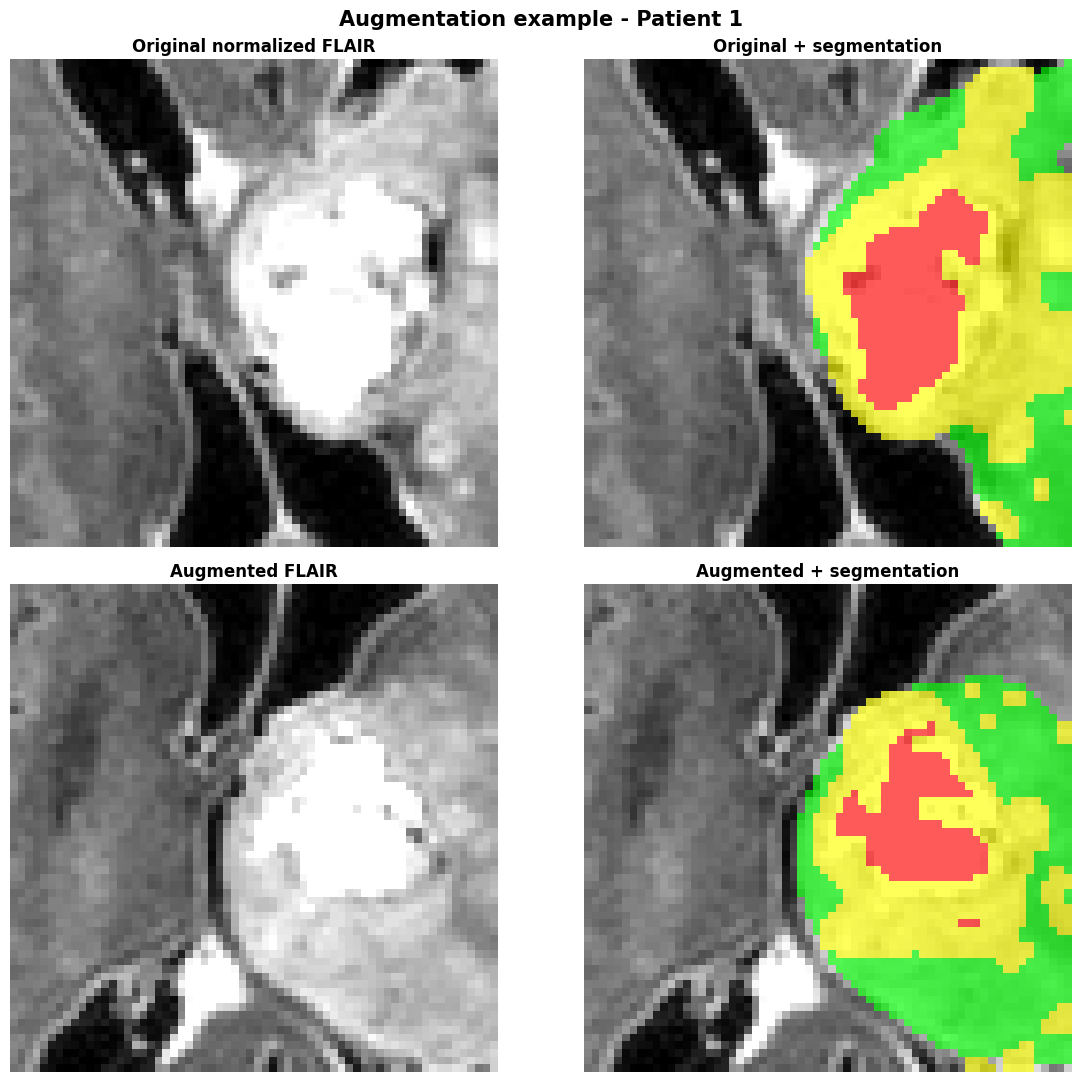

Patient: 1
Displayed axial slice: 34

Original mask labels: [0 1 2 3]
Augmented mask labels: [0 1 2 3]


In [10]:
# ================================================================
# CELL 17 - VISUALIZE PREPROCESSING AND AUGMENTATION
# ================================================================

def visualize_augmentation(
    dataframe,
    patient_index=0,
    slice_index=None
):
    """
    Visualize the effect of preprocessing and augmentation.

    Shows:
        1. Original normalized FLAIR
        2. Original segmentation
        3. Augmented FLAIR
        4. Augmented segmentation
    """

    row = dataframe.iloc[patient_index]

    # ------------------------------------------------------------
    # Load full patient volume
    # ------------------------------------------------------------

    image, mask, _ = load_patient_volumes(row)

    # ------------------------------------------------------------
    # Extract one patch
    # ------------------------------------------------------------

    original_image, original_mask = extract_3d_patch(
        image,
        mask,
        PATCH_SIZE,
        tumor_probability=1.0
    )

    # Make a copy before augmentation
    augmented_image = original_image.copy()
    augmented_mask = original_mask.copy()

    # ------------------------------------------------------------
    # Apply augmentation
    # ------------------------------------------------------------

    augmented_image, augmented_mask = augment_patch(
        augmented_image,
        augmented_mask
    )

    # ------------------------------------------------------------
    # Select slice
    # ------------------------------------------------------------

    if slice_index is None:

        # Prefer a slice containing tumor
        tumor_slices = np.where(
            original_mask.sum(axis=(0, 1)) > 0
        )[0]

        if len(tumor_slices) > 0:
            slice_index = int(
                tumor_slices[len(tumor_slices) // 2]
            )
        else:
            slice_index = PATCH_SIZE[2] // 2

    # ------------------------------------------------------------
    # Extract FLAIR slices
    # ------------------------------------------------------------

    original_flair = np.rot90(
        original_image[0, :, :, slice_index]
    )

    original_seg = np.rot90(
        original_mask[:, :, slice_index]
    )

    augmented_flair = np.rot90(
        augmented_image[0, :, :, slice_index]
    )

    augmented_seg = np.rot90(
        augmented_mask[:, :, slice_index]
    )

    # ------------------------------------------------------------
    # Plot
    # ------------------------------------------------------------

    fig, axes = plt.subplots(
        2,
        2,
        figsize=(12, 11)
    )

    # ------------------------------------------------------------
    # Fixed segmentation colormap
    # ------------------------------------------------------------

    seg_cmap = ListedColormap([
        (0, 0, 0, 0),       # background
        (1, 0, 0, 0.65),    # necrotic
        (0, 1, 0, 0.65),    # FLAIR hyperintensity
        (1, 1, 0, 0.65)     # enhancing
    ])

    # ------------------------------------------------------------
    # Original FLAIR
    # ------------------------------------------------------------

    axes[0, 0].imshow(
        original_flair,
        cmap="gray"
    )

    axes[0, 0].set_title(
        "Original normalized FLAIR",
        fontsize=12,
        fontweight="bold"
    )

    axes[0, 0].axis("off")

    # ------------------------------------------------------------
    # Original segmentation
    # ------------------------------------------------------------

    axes[0, 1].imshow(
        original_flair,
        cmap="gray"
    )

    axes[0, 1].imshow(
        original_seg,
        cmap=seg_cmap,
        vmin=0,
        vmax=3,
        interpolation="nearest"
    )

    axes[0, 1].set_title(
        "Original + segmentation",
        fontsize=12,
        fontweight="bold"
    )

    axes[0, 1].axis("off")

    # ------------------------------------------------------------
    # Augmented FLAIR
    # ------------------------------------------------------------

    axes[1, 0].imshow(
        augmented_flair,
        cmap="gray"
    )

    axes[1, 0].set_title(
        "Augmented FLAIR",
        fontsize=12,
        fontweight="bold"
    )

    axes[1, 0].axis("off")

    # ------------------------------------------------------------
    # Augmented segmentation
    # ------------------------------------------------------------

    axes[1, 1].imshow(
        augmented_flair,
        cmap="gray"
    )

    axes[1, 1].imshow(
        augmented_seg,
        cmap=seg_cmap,
        vmin=0,
        vmax=3,
        interpolation="nearest"
    )

    axes[1, 1].set_title(
        "Augmented + segmentation",
        fontsize=12,
        fontweight="bold"
    )

    axes[1, 1].axis("off")

    # ------------------------------------------------------------
    # Figure title
    # ------------------------------------------------------------

    plt.suptitle(
        f"Augmentation example - Patient {row['patient_folder']}",
        fontsize=15,
        fontweight="bold"
    )

    plt.tight_layout()

    plt.show()

    # ------------------------------------------------------------
    # Print information
    # ------------------------------------------------------------

    print(f"Patient: {row['patient_folder']}")
    print(f"Displayed axial slice: {slice_index}")

    print("\nOriginal mask labels:",
          np.unique(original_mask))

    print("Augmented mask labels:",
          np.unique(augmented_mask))


# ---------------------------------------------------------------
# Run visualization
# ---------------------------------------------------------------

visualize_augmentation(
    development_df,
    patient_index=0
)

## 3. Model: Swin UNETR

In [11]:
# ================================================================
# CELL 19 - SWIN UNETR ARCHITECTURE
# ================================================================
#
# Encoder (Swin Transformer):
#   1. Patch partition: the 4-channel volume is split into 2x2x2 patches,
#      each linearly embedded into FEATURE_SIZE channels (resolution / 2).
#   2. Four stages of Swin Transformer blocks. Each block alternates
#      window self-attention (W-MSA, 7x7x7 windows) and shifted-window
#      self-attention (SW-MSA), so information flows between windows.
#   3. Patch merging between stages: resolution / 2, channels x 2
#      (FEATURE_SIZE -> x2 -> x4 -> x8 -> x16).
#
# Decoder (CNN):
#   4. Encoder features at every resolution (plus the input itself) pass
#      through residual convolutional blocks and reach the decoder via
#      skip connections.
#   5. Each decoder level: transposed-convolution upsampling, concatenation
#      with the skip features, residual block.
#   6. A final 1x1x1 convolution produces NUM_CLASSES logits per voxel.
#
# With 64^3 patches the feature maps are 32^3, 16^3, 8^3, 4^3 and 2^3:
# when a feature map is smaller than the 7^3 window, MONAI shrinks the
# window to the feature-map size (global attention at the deepest stages).

def build_swin_unetr():
    """
    Builds a Swin UNETR that works with old and new MONAI versions
    (img_size is required before MONAI 1.5 and removed afterwards).
    """

    kwargs = dict(
        in_channels=NUM_INPUT_CHANNELS,
        out_channels=NUM_CLASSES,
        feature_size=FEATURE_SIZE,
        depths=DEPTHS,
        num_heads=NUM_HEADS,
        norm_name="instance",
        drop_rate=0.0,
        attn_drop_rate=0.0,
        dropout_path_rate=DROPOUT_PATH_RATE,
        normalize=True,
        use_checkpoint=USE_CHECKPOINT,
        spatial_dims=3
    )

    try:
        return SwinUNETR(**kwargs)
    except TypeError:
        return SwinUNETR(img_size=PATCH_SIZE, **kwargs)


print("Swin UNETR builder defined successfully.")

# ================================================================
# CELL 20 - MODEL INITIALIZATION AND SHAPE TEST
# ================================================================

model = build_swin_unetr()

# nn.DataParallel only if USE_DATA_PARALLEL = True
if use_multi_gpu():
    model = nn.DataParallel(model)

model = model.to(DEVICE)

base_model = model.module if isinstance(model, nn.DataParallel) else model

print("Top-level modules:")
for name, module in base_model.named_children():
    n_params = sum(p.numel() for p in module.parameters())
    print(f"  {name:12s} {type(module).__name__:28s} {n_params:>12,d} parameters")

# ---------------------------------------------------------------
# Parameter count
# ---------------------------------------------------------------
num_parameters = sum(
    p.numel() for p in model.parameters()
)

num_trainable_parameters = sum(
    p.numel()
    for p in model.parameters()
    if p.requires_grad
)

print("\nTotal parameters:", f"{num_parameters:,}")
print("Trainable parameters:", f"{num_trainable_parameters:,}")

# ---------------------------------------------------------------
# Forward-pass smoke test
# ---------------------------------------------------------------
with torch.no_grad():
    dummy_input = torch.randn(
        1,
        NUM_INPUT_CHANNELS,
        *PATCH_SIZE,
        device=DEVICE
    )

    dummy_output = model(dummy_input)

print("\nInput shape :", tuple(dummy_input.shape))
print("Output shape:", tuple(dummy_output.shape))

assert dummy_output.shape == (
    1,
    NUM_CLASSES,
    *PATCH_SIZE
)

assert torch.isfinite(dummy_output).all()

print("\nSwin UNETR forward pass: OK")

del model, base_model, dummy_input, dummy_output
release_cpu_memory()
if torch.cuda.is_available():
    torch.cuda.empty_cache()


Swin UNETR builder defined successfully.
Top-level modules:
  swinViT      SwinTransformer                   695,286 parameters
  encoder1     UnetrBasicBlock                     5,232 parameters
  encoder2     UnetrBasicBlock                     7,776 parameters
  encoder3     UnetrBasicBlock                    31,104 parameters
  encoder4     UnetrBasicBlock                   124,416 parameters
  encoder10    UnetrBasicBlock                 1,990,656 parameters
  decoder5     UnetrUpBlock                      912,384 parameters
  decoder4     UnetrUpBlock                      228,096 parameters
  decoder3     UnetrUpBlock                       57,024 parameters
  decoder2     UnetrUpBlock                       14,256 parameters
  decoder1     UnetrUpBlock                       13,104 parameters
  out          UnetOutBlock                           52 parameters

Total parameters: 4,079,386
Trainable parameters: 4,079,386

Input shape : (1, 4, 64, 64, 64)
Output shape: (1, 4, 64, 64, 

## 4. Loss and metrics (identical to the 3D U-Net baseline)

In [12]:
# ================================================================
# CELL 21 - LOSS FUNCTIONS
# ================================================================

class SoftDiceLoss(nn.Module):
    """
    Multi-class soft Dice loss.
    
    Background class (0) is excluded from the Dice calculation.
    """

    def __init__(self, smooth=1e-5):
        super().__init__()
        self.smooth = smooth

    def forward(self, logits, targets):
        """
        logits:
            [B, C, D, H, W]

        targets:
            [B, D, H, W]
        """

        num_classes = logits.shape[1]

        # Convert logits to probabilities
        probs = torch.softmax(logits, dim=1)

        # One-hot encode target
        targets_one_hot = F.one_hot(
            targets.long(),
            num_classes=num_classes
        )

        # [B, D, H, W, C] -> [B, C, D, H, W]
        targets_one_hot = targets_one_hot.permute(
            0, 4, 1, 2, 3
        ).float()

        # Exclude background
        probs = probs[:, 1:]
        targets_one_hot = targets_one_hot[:, 1:]

        # Flatten spatial dimensions
        probs = probs.reshape(
            probs.shape[0],
            probs.shape[1],
            -1
        )

        targets_one_hot = targets_one_hot.reshape(
            targets_one_hot.shape[0],
            targets_one_hot.shape[1],
            -1
        )

        # Dice per class and patient
        intersection = (
            probs * targets_one_hot
        ).sum(dim=2)

        denominator = (
            probs.sum(dim=2)
            + targets_one_hot.sum(dim=2)
        )

        dice = (
            2.0 * intersection + self.smooth
        ) / (
            denominator + self.smooth
        )

        # Mean across foreground classes and batch
        dice_loss = 1.0 - dice.mean()

        return dice_loss


class CombinedLoss(nn.Module):
    """
    Combined segmentation loss:

        0.5 * Cross Entropy
        +
        0.5 * Soft Dice
    """

    def __init__(
        self,
        ce_weight=0.5,
        dice_weight=0.5
    ):
        super().__init__()

        self.ce_weight = ce_weight
        self.dice_weight = dice_weight

        self.ce = nn.CrossEntropyLoss()
        self.dice = SoftDiceLoss()

    def forward(self, logits, targets):

        ce_loss = self.ce(logits, targets)
        dice_loss = self.dice(logits, targets)

        total_loss = (
            self.ce_weight * ce_loss
            +
            self.dice_weight * dice_loss
        )

        return total_loss, ce_loss, dice_loss


criterion = CombinedLoss(
    ce_weight=0.5,
    dice_weight=0.5
)

print("Loss functions defined successfully.")

# ================================================================
# CELL 23 - DICE AND IoU METRICS
# ================================================================

def dice_score_per_class(
    prediction,
    target,
    num_classes=NUM_CLASSES,
    include_background=False
):
    """
    Computes Dice score for each class.

    prediction:
        [B, D, H, W]

    target:
        [B, D, H, W]
    """

    scores = []

    start_class = 0 if include_background else 1

    for class_id in range(start_class, num_classes):

        pred_class = (prediction == class_id)
        target_class = (target == class_id)

        intersection = (
            pred_class & target_class
        ).sum().float()

        pred_volume = pred_class.sum().float()
        target_volume = target_class.sum().float()

        denominator = pred_volume + target_volume

        if denominator == 0:
            # Both prediction and target are empty
            dice = torch.tensor(
                1.0,
                device=prediction.device
            )
        else:
            dice = (
                2.0 * intersection
                / denominator
            )

        scores.append(dice.item())

    return scores


def iou_score_per_class(
    prediction,
    target,
    num_classes=NUM_CLASSES,
    include_background=False
):
    """
    Computes IoU score for each class.
    """

    scores = []

    start_class = 0 if include_background else 1

    for class_id in range(start_class, num_classes):

        pred_class = (prediction == class_id)
        target_class = (target == class_id)

        intersection = (
            pred_class & target_class
        ).sum().float()

        union = (
            pred_class | target_class
        ).sum().float()

        if union == 0:
            iou = torch.tensor(
                1.0,
                device=prediction.device
            )
        else:
            iou = intersection / union

        scores.append(iou.item())

    return scores


print("Dice and IoU metric functions defined successfully.")

Loss functions defined successfully.
Dice and IoU metric functions defined successfully.


## 5. Training

Same training loop as the baseline. Differences: warm-up + cosine learning-rate schedule, gradient clipping, sliding-window inference in validation. The loop reads data from the cache, saves a resumable checkpoint after every epoch and stops cleanly before the session time limit.

Memory: the model runs on **one GPU** by default (`USE_DATA_PARALLEL = False`): with `nn.DataParallel` the RAM of the notebook process grew by about 10 GB per epoch until the kernel died. The total batch is unchanged, so the results do not depend on it. A memory budget stops the session cleanly (like the time budget) if the RAM keeps growing.

Validation runs on **two GPUs without `nn.DataParallel`** (`VALIDATION_GPUS = 2`): the two volumes of each validation batch are predicted in parallel, one per GPU, with the same sliding-window inference and the same weights, so loss and metrics do not change. Training stays on one GPU.


In [13]:
# ================================================================
# CELL 25 - TRAINING UTILITIES
# ================================================================

from tqdm.auto import tqdm


def get_model_state_dict(model):
    """
    Returns the state_dict independently of whether
    the model is wrapped in DataParallel.
    """
    if isinstance(model, nn.DataParallel):
        return model.module.state_dict()
    return model.state_dict()


def create_model():
    """
    Creates a fresh Swin UNETR for each fold.
    """

    model = build_swin_unetr()

    if use_multi_gpu():
        model = nn.DataParallel(model)

    model = model.to(DEVICE)

    return model


def load_model_from_checkpoint(checkpoint_path):
    """
    Loads the weights into an unwrapped model and wraps it afterwards
    (the checkpoint is saved without the 'module.' prefix of DataParallel).
    """

    checkpoint = torch.load(
        checkpoint_path,
        map_location="cpu",
        weights_only=False
    )

    model = build_swin_unetr()
    model.load_state_dict(checkpoint["model_state_dict"])

    if use_multi_gpu():
        model = nn.DataParallel(model)

    model = model.to(DEVICE)
    model.eval()

    return model, checkpoint


def create_optimizer(model):
    """
    AdamW optimizer (same settings as the 3D U-Net baseline).
    """

    return torch.optim.AdamW(
        model.parameters(),
        lr=LEARNING_RATE,
        weight_decay=WEIGHT_DECAY
    )


def create_scheduler(optimizer):
    """
    Linear warm-up for WARMUP_EPOCHS, then cosine decay to zero at MAX_EPOCHS.
    The scheduler is stepped once per epoch.
    """

    def lr_lambda(completed_epochs):

        if completed_epochs < WARMUP_EPOCHS:
            return (completed_epochs + 1) / WARMUP_EPOCHS

        progress = (completed_epochs - WARMUP_EPOCHS) / max(1, MAX_EPOCHS - WARMUP_EPOCHS)

        return 0.5 * (1.0 + math.cos(math.pi * min(progress, 1.0)))

    return torch.optim.lr_scheduler.LambdaLR(optimizer, lr_lambda)


def predict_logits(model, images):
    """
    Full-volume logits with sliding-window inference.

    Swin UNETR needs inputs divisible by 32; 240 x 240 x 155 is not.
    The volume is processed in PATCH_SIZE windows (overlap SW_OVERLAP)
    blended with Gaussian weights, and the output has the same spatial
    size as the input, so loss and metrics are computed on the full
    volume exactly as in the 3D U-Net baseline.
    """

    return sliding_window_inference(
        inputs=images,
        roi_size=PATCH_SIZE,
        sw_batch_size=SW_BATCH_SIZE,
        predictor=model,
        overlap=SW_OVERLAP,
        mode=SW_MODE
    )


def compute_batch_metrics(logits, targets):
    """
    Computes mean Dice and IoU across the foreground classes
    for a batch (identical to the 3D U-Net baseline).
    """

    predictions = torch.argmax(logits, dim=1)

    dice_values = dice_score_per_class(
        predictions,
        targets,
        num_classes=NUM_CLASSES,
        include_background=False
    )

    iou_values = iou_score_per_class(
        predictions,
        targets,
        num_classes=NUM_CLASSES,
        include_background=False
    )

    return (
        float(np.mean(dice_values)),
        float(np.mean(iou_values))
    )


# ================================================================
# VALIDATION ON TWO GPUs (without nn.DataParallel)
# ================================================================
# The volumes of a validation batch are predicted in parallel, one per GPU.
# nn.DataParallel is NOT used: it leaked ~1.6 MB of RAM per call because it
# copies the model and starts new threads at every forward. Here:
#   - each GPU keeps its own copy of the model, refreshed once per validation (sync);
#   - the work goes to worker threads created once for the whole session.
# Each volume goes through exactly the same sliding-window inference with the
# same weights, so the predictions do not change (rounding-level differences only).

import contextlib
from concurrent.futures import ThreadPoolExecutor


class MultiGPUSlidingWindow:

    def __init__(self, num_gpus):

        if torch.cuda.is_available():
            num_gpus = max(1, min(num_gpus, torch.cuda.device_count()))
            self.devices = [torch.device("cuda", i) for i in range(num_gpus)]
        else:
            self.devices = [torch.device("cpu")]

        self.models = [None] * len(self.devices)

        self.pool = (
            ThreadPoolExecutor(max_workers=len(self.devices), thread_name_prefix="sliding_window")
            if len(self.devices) > 1 else None
        )

    def sync(self, model):
        """Uses the current weights of `model` on every GPU (once per validation)."""

        source = model.module if isinstance(model, nn.DataParallel) else model
        source.eval()
        self.models[0] = source

        if len(self.devices) > 1:

            state = source.state_dict()

            for i, device in enumerate(self.devices[1:], start=1):

                if self.models[i] is None:
                    self.models[i] = build_swin_unetr().to(device)

                self.models[i].load_state_dict(state)
                self.models[i].eval()

    def _predict_on(self, index, images):

        device = self.devices[index]

        device_context = (
            torch.cuda.device(device) if device.type == "cuda" else contextlib.nullcontext()
        )

        # Gradient and autocast settings are per thread: they are set here
        with device_context, torch.no_grad(), torch.autocast(
            device_type="cuda", enabled=device.type == "cuda"
        ):
            return predict_logits(
                self.models[index],
                images.to(device, non_blocking=True)
            ).float()

    def predict(self, images):
        """images [B, C, D, H, W] (CPU or GPU) -> float logits [B, classes, D, H, W] on DEVICE."""

        chunks = torch.tensor_split(images, min(len(self.devices), images.shape[0]))

        if self.pool is None or len(chunks) == 1:
            outputs = [self._predict_on(0, images)]
        else:
            futures = [
                self.pool.submit(self._predict_on, i, chunk)
                for i, chunk in enumerate(chunks)
            ]
            outputs = [future.result() for future in futures]

        return torch.cat([output.to(DEVICE) for output in outputs], dim=0)


VALIDATION_PREDICTOR = MultiGPUSlidingWindow(VALIDATION_GPUS)

print("GPUs used for validation and evaluation:", len(VALIDATION_PREDICTOR.devices))
print("Training utilities defined successfully.")

# ================================================================
# CELL 26 - TRAIN ONE EPOCH
# ================================================================

def train_one_epoch(
    model,
    loader,
    optimizer,
    criterion,
    scaler
):
    model.train()

    running_loss = 0.0
    running_ce = 0.0
    running_dice_loss = 0.0

    running_dice = 0.0
    running_iou = 0.0

    num_batches = 0

    progress_bar = tqdm(
        loader,
        desc="Training",
        leave=False
    )

    for batch in progress_bar:

        images = batch["image"].to(
            DEVICE,
            non_blocking=True
        )

        masks = batch["mask"].to(
            DEVICE,
            non_blocking=True
        )

        optimizer.zero_grad(set_to_none=True)

        # --------------------------------------------------------
        # Mixed precision forward pass
        # --------------------------------------------------------
        with torch.cuda.amp.autocast(
            enabled=torch.cuda.is_available()
        ):

            logits = model(images)

            total_loss, ce_loss, dice_loss = criterion(
                logits,
                masks
            )

        # --------------------------------------------------------
        # Backpropagation (+ gradient clipping for the transformer)
        # --------------------------------------------------------
        scaler.scale(total_loss).backward()

        if GRAD_CLIP_NORM is not None:
            scaler.unscale_(optimizer)
            torch.nn.utils.clip_grad_norm_(
                model.parameters(),
                GRAD_CLIP_NORM
            )

        scaler.step(optimizer)
        scaler.update()

        # --------------------------------------------------------
        # Metrics
        # --------------------------------------------------------
        batch_dice, batch_iou = compute_batch_metrics(
            logits.detach(),
            masks
        )

        running_loss += total_loss.item()
        running_ce += ce_loss.item()
        running_dice_loss += dice_loss.item()

        running_dice += batch_dice
        running_iou += batch_iou

        num_batches += 1

        progress_bar.set_postfix(
            loss=f"{total_loss.item():.4f}",
            dice=f"{batch_dice:.4f}"
        )

        # Memory management only (no effect on the training)
        if num_batches % TRIM_EVERY_TRAIN_BATCHES == 0:
            release_cpu_memory()

        if MEMORY_EMERGENCY.is_set():
            raise MemoryError("RAM almost full during training.")

    return {
        "loss": running_loss / num_batches,
        "ce_loss": running_ce / num_batches,
        "dice_loss": running_dice_loss / num_batches,
        "dice": running_dice / num_batches,
        "iou": running_iou / num_batches
    }

# ================================================================
# CELL 27 - VALIDATION (full volumes, sliding-window inference)
# ================================================================

def validate_one_epoch(
    model,
    loader,
    criterion
):
    model.eval()

    # Current weights on every validation GPU (one copy per epoch)
    VALIDATION_PREDICTOR.sync(model)

    running_loss = 0.0
    running_ce = 0.0
    running_dice_loss = 0.0

    running_dice = 0.0
    running_iou = 0.0

    num_batches = 0

    with torch.no_grad():

        progress_bar = tqdm(
            loader,
            desc="Validation",
            leave=False
        )

        for batch in progress_bar:

            # Each volume is moved to its own GPU by the predictor
            images = batch["image"]

            masks = batch["mask"].to(
                DEVICE,
                non_blocking=True
            )

            with torch.cuda.amp.autocast(
                enabled=torch.cuda.is_available()
            ):

                # Same sliding-window logits as predict_logits(model, images),
                # computed with one volume per GPU
                logits = VALIDATION_PREDICTOR.predict(images)

                total_loss, ce_loss, dice_loss = criterion(
                    logits,
                    masks
                )

            batch_dice, batch_iou = compute_batch_metrics(
                logits,
                masks
            )

            running_loss += total_loss.item()
            running_ce += ce_loss.item()
            running_dice_loss += dice_loss.item()

            running_dice += batch_dice
            running_iou += batch_iou

            num_batches += 1

            progress_bar.set_postfix(
                loss=f"{total_loss.item():.4f}",
                dice=f"{batch_dice:.4f}"
            )

            # Memory management only (no effect on the metrics)
            del images, masks, logits

            if num_batches % TRIM_EVERY_VAL_BATCHES == 0:
                release_cpu_memory()

            if MEMORY_EMERGENCY.is_set():
                raise MemoryError("RAM almost full during validation.")

    return {
        "loss": running_loss / num_batches,
        "ce_loss": running_ce / num_batches,
        "dice_loss": running_dice_loss / num_batches,
        "dice": running_dice / num_batches,
        "iou": running_iou / num_batches
    }


print("Training and validation functions defined successfully.")


GPUs used for validation and evaluation: 2
Training utilities defined successfully.
Training and validation functions defined successfully.


In [14]:
# ================================================================
# CELL 28 - CROSS-VALIDATION TRAINING (resumable)
# ================================================================

set_seed(SEED)

all_fold_results = []
all_fold_histories = []

fold_completed = {}
SESSION_STOPPED = False


def hours_used():
    return (time.time() - NOTEBOOK_START_TIME) / 3600


# ---------------------------------------------------------------
# Memory monitor: a "Kernel died" without a Python error is almost
# always the system running out of RAM. This logs RAM and shared
# memory every MEMORY_LOG_SECONDS and prints a warning above 85%.
# ---------------------------------------------------------------
import threading

try:
    import psutil
except ImportError:
    psutil = None


def memory_snapshot():
    """
    System RAM + private memory (USS, shared pages counted once) of the
    notebook process and of its DataLoader workers.
    """

    if psutil is None:
        return {}

    vm = psutil.virtual_memory()
    main_process = psutil.Process()

    try:
        main_gb = main_process.memory_full_info().uss / 1e9
    except psutil.Error:
        main_gb = main_process.memory_info().rss / 1e9

    workers_gb = 0.0

    for child in main_process.children(recursive=True):
        try:
            workers_gb += child.memory_full_info().uss / 1e9
        except psutil.Error:
            pass

    shm = shutil.disk_usage("/dev/shm") if Path("/dev/shm").exists() else None

    return {
        "ram_used_gb": vm.used / 1e9,
        "ram_available_gb": vm.available / 1e9,
        "ram_total_gb": vm.total / 1e9,
        "ram_percent": vm.percent,
        "notebook_process_gb": main_gb,
        "workers_gb": workers_gb,
        "threads": main_process.num_threads(),
        "shm_used_gb": shm.used / 1e9 if shm else float("nan"),
        "shm_total_gb": shm.total / 1e9 if shm else float("nan")
    }


def memory_summary():

    s = memory_snapshot()

    if not s:
        return "memory: psutil not available"

    return (
        f"RAM {s['ram_used_gb']:.1f}/{s['ram_total_gb']:.1f} GB ({s['ram_percent']:.0f}%) "
        f"| notebook process {s['notebook_process_gb']:.1f} GB "
        f"| workers {s['workers_gb']:.1f} GB "
        f"| threads {s['threads']} "
        f"| /dev/shm {s['shm_used_gb']:.1f}/{s['shm_total_gb']:.1f} GB"
    )


class MemoryMonitor(threading.Thread):

    def __init__(self, path, interval):
        super().__init__(daemon=True)
        self.path = path
        self.interval = interval
        self.stop_event = threading.Event()

    def run(self):

        while not self.stop_event.wait(self.interval):

            snapshot = memory_snapshot()

            if not snapshot:
                return

            snapshot["hours"] = hours_used()

            pd.DataFrame([snapshot]).to_csv(
                self.path,
                mode="a",
                header=not self.path.exists(),
                index=False
            )

            if snapshot["ram_percent"] > EMERGENCY_RAM_PERCENT:
                MEMORY_EMERGENCY.set()

            if snapshot["ram_percent"] > 80:
                print(f"\n⚠ HIGH MEMORY USAGE: {memory_summary()}", flush=True)

    def stop(self):
        self.stop_event.set()


# One memory log per session (a resumed session also copies the previous logs)
MEMORY_LOG_PATH = RESULTS_DIR / f"memory_log_{time.strftime('%Y%m%d_%H%M')}.csv"

MEMORY_EMERGENCY.clear()
memory_monitor = MemoryMonitor(MEMORY_LOG_PATH, MEMORY_LOG_SECONDS)
memory_monitor.start()

print("Memory before training:", memory_summary())


def unwrap_model(model):
    return model.module if isinstance(model, nn.DataParallel) else model


def capture_rng_state():
    return {
        "python": random.getstate(),
        "numpy": np.random.get_state(),
        "torch": torch.get_rng_state(),
        "cuda": torch.cuda.get_rng_state_all() if torch.cuda.is_available() else None
    }


def restore_rng_state(state):

    random.setstate(state["python"])
    np.random.set_state(state["numpy"])
    torch.set_rng_state(state["torch"])

    if (
        state["cuda"] is not None
        and torch.cuda.is_available()
        and len(state["cuda"]) == torch.cuda.device_count()
    ):
        torch.cuda.set_rng_state_all(state["cuda"])


# ===============================================================
# LOOP OVER THE FOLDS
# ===============================================================

for fold in FOLDS_TO_RUN:

    print("\n")
    print("=" * 70)
    print(f"STARTING FOLD {fold}")
    print("=" * 70)

    train_fold_df, val_fold_df = get_fold_split(fold)

    print(f"Training patients   : {len(train_fold_df)}")
    print(f"Validation patients : {len(val_fold_df)}")

    best_path = CHECKPOINT_DIR / f"swin_unetr_fold{fold}_best.pth"
    last_path = CHECKPOINT_DIR / f"swin_unetr_fold{fold}_last.pth"

    # -----------------------------------------------------------
    # Fresh model, optimizer, scheduler, loss, scaler
    # -----------------------------------------------------------
    model = create_model()
    optimizer = create_optimizer(model)
    scheduler = create_scheduler(optimizer)

    criterion = CombinedLoss(
        ce_weight=0.5,
        dice_weight=0.5
    )

    scaler = torch.cuda.amp.GradScaler(
        enabled=torch.cuda.is_available()
    )

    history = []

    best_val_loss = float("inf")
    best_val_dice = -float("inf")

    epochs_without_improvement = 0
    best_epoch = 0
    start_epoch = 1
    finished = False

    # -----------------------------------------------------------
    # Resume from the last checkpoint of this fold, if present
    # -----------------------------------------------------------
    if last_path.exists():

        state = torch.load(last_path, map_location="cpu", weights_only=False)

        unwrap_model(model).load_state_dict(state["model_state_dict"])
        optimizer.load_state_dict(state["optimizer_state_dict"])
        scheduler.load_state_dict(state["scheduler_state_dict"])
        scaler.load_state_dict(state["scaler_state_dict"])

        history = state["history"]
        best_val_loss = state["best_val_loss"]
        best_val_dice = state["best_val_dice"]
        best_epoch = state["best_epoch"]
        epochs_without_improvement = state["epochs_without_improvement"]
        start_epoch = state["epoch"] + 1
        finished = state["finished"]

        restore_rng_state(state["rng_state"])

        print(
            f"Resumed from epoch {state['epoch']} "
            f"(best epoch {best_epoch}, best val loss {best_val_loss:.4f})"
        )

        if finished:
            print("Training of this fold was already completed: skipping to the results.")

    train_loader = None
    val_loader = None
    stopped_for_time = False
    stopped_for_memory = False

    if not finished:

        train_dataset = CachedGlioma3DDataset(train_fold_df, training=True)
        val_dataset = CachedGlioma3DDataset(val_fold_df, training=False)

        # Workers are NOT persistent: they are recreated at every epoch,
        # so any memory they accumulate is released.
        train_loader = DataLoader(
            train_dataset,
            batch_size=BATCH_SIZE,
            shuffle=True,
            num_workers=NUM_WORKERS,
            pin_memory=torch.cuda.is_available(),
            persistent_workers=False
        )

        # Validation batches are full volumes (~0.3 GB each):
        # fewer workers, no prefetch queue, no pinned-memory copies.
        val_loader_kwargs = dict(
            batch_size=BATCH_SIZE,
            shuffle=False,
            num_workers=VAL_NUM_WORKERS,
            pin_memory=False,
            persistent_workers=False
        )

        if VAL_NUM_WORKERS > 0:
            val_loader_kwargs["prefetch_factor"] = 1

        val_loader = DataLoader(val_dataset, **val_loader_kwargs)

        print(f"Training patches per epoch   : {len(train_dataset)}")
        print(f"Validation samples per epoch : {len(val_dataset)}")

    # RAM growth of the last epoch (for the memory budget)
    previous_ram_gb = memory_snapshot().get("ram_used_gb")
    epoch_ram_growth_gb = None

    # ===========================================================
    # EPOCH LOOP
    # ===========================================================

    for epoch in range(start_epoch, MAX_EPOCHS + 1):

        if finished:
            break

        # -------------------------------------------------------
        # Session time budget: do not start an epoch that would
        # not finish before MAX_SESSION_HOURS
        # -------------------------------------------------------
        recent_epoch_hours = (
            np.mean([h["epoch_time_seconds"] for h in history[-5:]]) / 3600
            if history else 0.0
        )

        if hours_used() + 1.15 * recent_epoch_hours > MAX_SESSION_HOURS:

            stopped_for_time = True

            print(
                f"\n⏸ SESSION TIME BUDGET REACHED ({hours_used():.2f} h used): "
                f"training of fold {fold} stops after epoch {epoch - 1}. "
                "Resume it in the next session with RESUME_FROM."
            )

            break

        # -------------------------------------------------------
        # Memory budget: do not start an epoch that would fill the RAM
        # -------------------------------------------------------
        if epoch_ram_growth_gb is not None and psutil is not None:

            vm = psutil.virtual_memory()

            predicted_percent = 100 * (
                vm.total - vm.available + 1.2 * max(epoch_ram_growth_gb, 0.0) * 1e9
            ) / vm.total

            if predicted_percent > MAX_RAM_PERCENT:

                stopped_for_memory = True

                print(
                    f"\n⏸ MEMORY BUDGET REACHED: RAM {vm.percent:.0f}% and "
                    f"+{epoch_ram_growth_gb:.1f} GB in the last epoch. Training of fold {fold} "
                    f"stops after epoch {epoch - 1}. Resume it in the next session with RESUME_FROM."
                )

                break

        epoch_start_time = time.time()

        current_lr = optimizer.param_groups[0]["lr"]

        print("\n")
        print("-" * 70)
        print(f"Fold {fold} | Epoch {epoch}/{MAX_EPOCHS} | LR {current_lr:.2e}")
        print("-" * 70)

        # -------------------------------------------------------
        # Training and validation (same functions as before)
        # -------------------------------------------------------
        try:

            train_metrics = train_one_epoch(
                model,
                train_loader,
                optimizer,
                criterion,
                scaler
            )

            release_cpu_memory()
            ram_after_train_gb = memory_snapshot().get("ram_used_gb", float("nan"))

            val_metrics = validate_one_epoch(
                model,
                val_loader,
                criterion
            )

        except MemoryError as error:

            # The epoch is discarded: last checkpoint = previous epoch
            stopped_for_memory = True
            release_cpu_memory()

            print(
                f"\n⛔ {error} Epoch {epoch} interrupted; training of fold {fold} resumes "
                f"from epoch {epoch} in the next session (RESUME_FROM)."
            )

            break

        scheduler.step()

        # Release memory held by the validation volumes before the next epoch
        release_cpu_memory()

        if torch.cuda.is_available():
            torch.cuda.empty_cache()

        epoch_time = time.time() - epoch_start_time

        memory_now = memory_snapshot()

        if previous_ram_gb is not None and "ram_used_gb" in memory_now:
            epoch_ram_growth_gb = memory_now["ram_used_gb"] - previous_ram_gb
            previous_ram_gb = memory_now["ram_used_gb"]

        epoch_result = {
            "fold": fold,
            "epoch": epoch,
            "learning_rate": current_lr,

            "train_loss": train_metrics["loss"],
            "train_ce_loss": train_metrics["ce_loss"],
            "train_dice_loss": train_metrics["dice_loss"],
            "train_dice": train_metrics["dice"],
            "train_iou": train_metrics["iou"],

            "val_loss": val_metrics["loss"],
            "val_ce_loss": val_metrics["ce_loss"],
            "val_dice_loss": val_metrics["dice_loss"],
            "val_dice": val_metrics["dice"],
            "val_iou": val_metrics["iou"],

            "epoch_time_seconds": epoch_time,

            "ram_percent": memory_now.get("ram_percent", float("nan")),
            "ram_used_gb": memory_now.get("ram_used_gb", float("nan")),
            "ram_after_train_gb": ram_after_train_gb,
            "notebook_process_gb": memory_now.get("notebook_process_gb", float("nan")),
            "shm_used_gb": memory_now.get("shm_used_gb", float("nan")),
            "data_parallel": use_multi_gpu()
        }

        history.append(epoch_result)

        pd.DataFrame(history).to_csv(
            RESULTS_DIR / f"fold_{fold}_history.csv",
            index=False
        )

        # -------------------------------------------------------
        # Epoch summary and progress
        # -------------------------------------------------------
        print(
            f"\nTrain loss: {train_metrics['loss']:.4f}"
            f" | Train Dice: {train_metrics['dice']:.4f}"
            f" | Train IoU: {train_metrics['iou']:.4f}"
        )

        print(
            f"Val loss:   {val_metrics['loss']:.4f}"
            f" | Val Dice:   {val_metrics['dice']:.4f}"
            f" | Val IoU:    {val_metrics['iou']:.4f}"
        )

        mean_epoch_minutes = np.mean([h["epoch_time_seconds"] for h in history]) / 60
        remaining_epochs = MAX_EPOCHS - epoch

        print(
            f"Epoch time: {epoch_time / 60:.2f} min "
            f"| mean {mean_epoch_minutes:.1f} min/epoch "
            f"| at most {remaining_epochs * mean_epoch_minutes / 60:.1f} h left for this fold "
            f"(less with early stopping) "
            f"| session time used {hours_used():.2f}/{MAX_SESSION_HOURS} h"
        )

        print("Memory:", memory_summary())

        if epoch_ram_growth_gb is not None:
            print(f"RAM change in this epoch: {epoch_ram_growth_gb:+.1f} GB")

        # -------------------------------------------------------
        # Best checkpoint (same criterion as the baseline: val loss)
        # -------------------------------------------------------
        if val_metrics["loss"] < best_val_loss:

            best_val_loss = val_metrics["loss"]
            best_val_dice = val_metrics["dice"]
            best_epoch = epoch

            epochs_without_improvement = 0

            torch.save({
                "fold": fold,
                "epoch": epoch,
                "model_state_dict": get_model_state_dict(model),
                "best_val_loss": best_val_loss,
                "best_val_dice": best_val_dice,
                "config": {
                    "architecture": "Swin UNETR",
                    "patch_size": PATCH_SIZE,
                    "batch_size": BATCH_SIZE,
                    "feature_size": FEATURE_SIZE,
                    "depths": DEPTHS,
                    "num_heads": NUM_HEADS,
                    "learning_rate": LEARNING_RATE,
                    "weight_decay": WEIGHT_DECAY,
                    "warmup_epochs": WARMUP_EPOCHS,
                    "grad_clip_norm": GRAD_CLIP_NORM,
                    "num_classes": NUM_CLASSES,
                    "num_input_channels": NUM_INPUT_CHANNELS
                }
            }, best_path)

            print(f"✓ Best checkpoint saved: {best_path.name}")

        else:

            epochs_without_improvement += 1

            print(f"No improvement for {epochs_without_improvement} epoch(s).")

        # -------------------------------------------------------
        # Early stopping / end of training
        # -------------------------------------------------------
        if epochs_without_improvement >= PATIENCE:

            print(f"\nEarly stopping triggered after {PATIENCE} epochs without improvement.")
            finished = True

        if epoch == MAX_EPOCHS:
            finished = True

        # -------------------------------------------------------
        # Last checkpoint: everything needed to resume
        # -------------------------------------------------------
        torch.save({
            "epoch": epoch,
            "finished": finished,
            "model_state_dict": get_model_state_dict(model),
            "optimizer_state_dict": optimizer.state_dict(),
            "scheduler_state_dict": scheduler.state_dict(),
            "scaler_state_dict": scaler.state_dict(),
            "history": history,
            "best_val_loss": best_val_loss,
            "best_val_dice": best_val_dice,
            "best_epoch": best_epoch,
            "epochs_without_improvement": epochs_without_improvement,
            "rng_state": capture_rng_state()
        }, last_path)

    # ===========================================================
    # END OF FOLD
    # ===========================================================

    fold_completed[fold] = finished

    if history:

        history_df = pd.DataFrame(history)

        history_df.to_csv(
            RESULTS_DIR / f"fold_{fold}_history.csv",
            index=False
        )

        best_row = history_df.loc[history_df["val_loss"].idxmin()]

        fold_result = {
            "fold": fold,
            "completed": finished,
            "epochs_trained": len(history_df),
            "best_epoch": int(best_row["epoch"]),
            "best_val_loss": float(best_row["val_loss"]),
            "best_val_dice": float(best_row["val_dice"]),
            "best_val_iou": float(best_row["val_iou"]),
            "training_time_minutes": float(history_df["epoch_time_seconds"].sum() / 60.0),
            "mean_epoch_minutes": float(history_df["epoch_time_seconds"].mean() / 60.0),
            "num_parameters": int(sum(p.numel() for p in model.parameters()))
        }

        all_fold_results.append(fold_result)
        all_fold_histories.append(history_df)

        print("\n")
        print("=" * 70)
        print(f"FOLD {fold} {'COMPLETED' if finished else 'PAUSED'}")
        print("=" * 70)

        print(f"Epochs trained : {fold_result['epochs_trained']}")
        print(f"Best epoch     : {fold_result['best_epoch']}")
        print(f"Best val loss  : {fold_result['best_val_loss']:.4f}")
        print(f"Best val Dice  : {fold_result['best_val_dice']:.4f}")
        print(f"Best val IoU   : {fold_result['best_val_iou']:.4f}")
        print(f"Training time  : {fold_result['training_time_minutes']:.2f} min")

    # -----------------------------------------------------------
    # Free memory before next fold
    # -----------------------------------------------------------
    model = optimizer = scheduler = scaler = None
    train_loader = val_loader = None

    release_cpu_memory()

    if torch.cuda.is_available():
        torch.cuda.empty_cache()

    if stopped_for_time or stopped_for_memory:
        SESSION_STOPPED = True
        break


# ===============================================================
# SAVE CV SUMMARY
# ===============================================================

fold_results_df = pd.DataFrame(all_fold_results)

fold_results_path = RESULTS_DIR / "5fold_summary.csv"

fold_results_df.to_csv(fold_results_path, index=False)

print("\n")
print("=" * 70)
print("TRAINING SESSION FINISHED" if not SESSION_STOPPED else "TRAINING SESSION PAUSED")
print("=" * 70)

if len(fold_results_df):

    display(fold_results_df)

    completed_df = fold_results_df[fold_results_df["completed"]]

    if len(completed_df):
        print("\nMean validation Dice (completed folds):", completed_df["best_val_dice"].mean())
        print("Std validation Dice (completed folds):", completed_df["best_val_dice"].std())
        print("\nMean validation IoU (completed folds):", completed_df["best_val_iou"].mean())
        print("Std validation IoU (completed folds):", completed_df["best_val_iou"].std())

if SESSION_STOPPED:
    print(
        "\nTo continue: Save Version, then in a new session add this version's output as "
        f"input and set RESUME_FROM to its {OUTPUT_DIR.name} folder."
    )

memory_monitor.stop()

print("\nResults saved to:", fold_results_path)
print(f"Session time used: {hours_used():.2f} h")
print("Memory at the end of training:", memory_summary())


Memory before training: RAM 2.8/33.7 GB (10%) | notebook process 2.5 GB | workers 0.0 GB | threads 23 | /dev/shm 0.0/15.0 GB


STARTING FOLD 0
Training patients   : 802
Validation patients : 201
Resumed from epoch 21 (best epoch 20, best val loss 0.1622)
Training patches per epoch   : 1604
Validation samples per epoch : 201


----------------------------------------------------------------------
Fold 0 | Epoch 22/50 | LR 7.19e-05
----------------------------------------------------------------------


Training:   0%|          | 0/802 [00:00<?, ?it/s]

Validation:   0%|          | 0/101 [00:00<?, ?it/s]


Train loss: 0.2535 | Train Dice: 0.8068 | Train IoU: 0.7228
Val loss:   0.1678 | Val Dice:   0.8101 | Val IoU:    0.7094
Epoch time: 16.06 min | mean 27.3 min/epoch | at most 12.8 h left for this fold (less with early stopping) | session time used 0.66/10.5 h
Memory: RAM 3.8/33.7 GB (15%) | notebook process 3.6 GB | workers 0.0 GB | threads 29 | /dev/shm 0.3/15.0 GB
RAM change in this epoch: +1.2 GB
No improvement for 2 epoch(s).


----------------------------------------------------------------------
Fold 0 | Epoch 23/50 | LR 6.87e-05
----------------------------------------------------------------------


Training:   0%|          | 0/802 [00:00<?, ?it/s]

Validation:   0%|          | 0/101 [00:00<?, ?it/s]

... (80 outputs left out)

Validation:   0%|          | 0/101 [00:00<?, ?it/s]


Train loss: 0.2315 | Train Dice: 0.8360 | Train IoU: 0.7559
Val loss:   0.1291 | Val Dice:   0.8404 | Val IoU:    0.7506
Epoch time: 16.07 min | mean 21.0 min/epoch | at most 0.0 h left for this fold (less with early stopping) | session time used 8.16/10.5 h
Memory: RAM 3.7/33.7 GB (16%) | notebook process 3.1 GB | workers 0.0 GB | threads 29 | /dev/shm 0.7/15.0 GB
RAM change in this epoch: -0.0 GB
No improvement for 2 epoch(s).


FOLD 0 COMPLETED
Epochs trained : 50
Best epoch     : 48
Best val loss  : 0.1291
Best val Dice  : 0.8404
Best val IoU   : 0.7506
Training time  : 1051.26 min


TRAINING SESSION FINISHED


,fold,completed,epochs_trained,best_epoch,best_val_loss,best_val_dice,best_val_iou,training_time_minutes,mean_epoch_minutes,num_parameters
0,0,True,50,48,0.129091,0.840372,0.750605,1051.255768,21.025115,4079386



Mean validation Dice (completed folds): 0.8403720696681108
Std validation Dice (completed folds): nan

Mean validation IoU (completed folds): 0.750605386503582
Std validation IoU (completed folds): nan

Results saved to: /kaggle/working/glioma_swin_unetr_fs12/results/5fold_summary.csv
Session time used: 8.16 h
Memory at the end of training: RAM 3.7/33.7 GB (13%) | notebook process 3.1 GB | workers 0.0 GB | threads 28 | /dev/shm 0.0/15.0 GB


## 6. Training curves and qualitative results

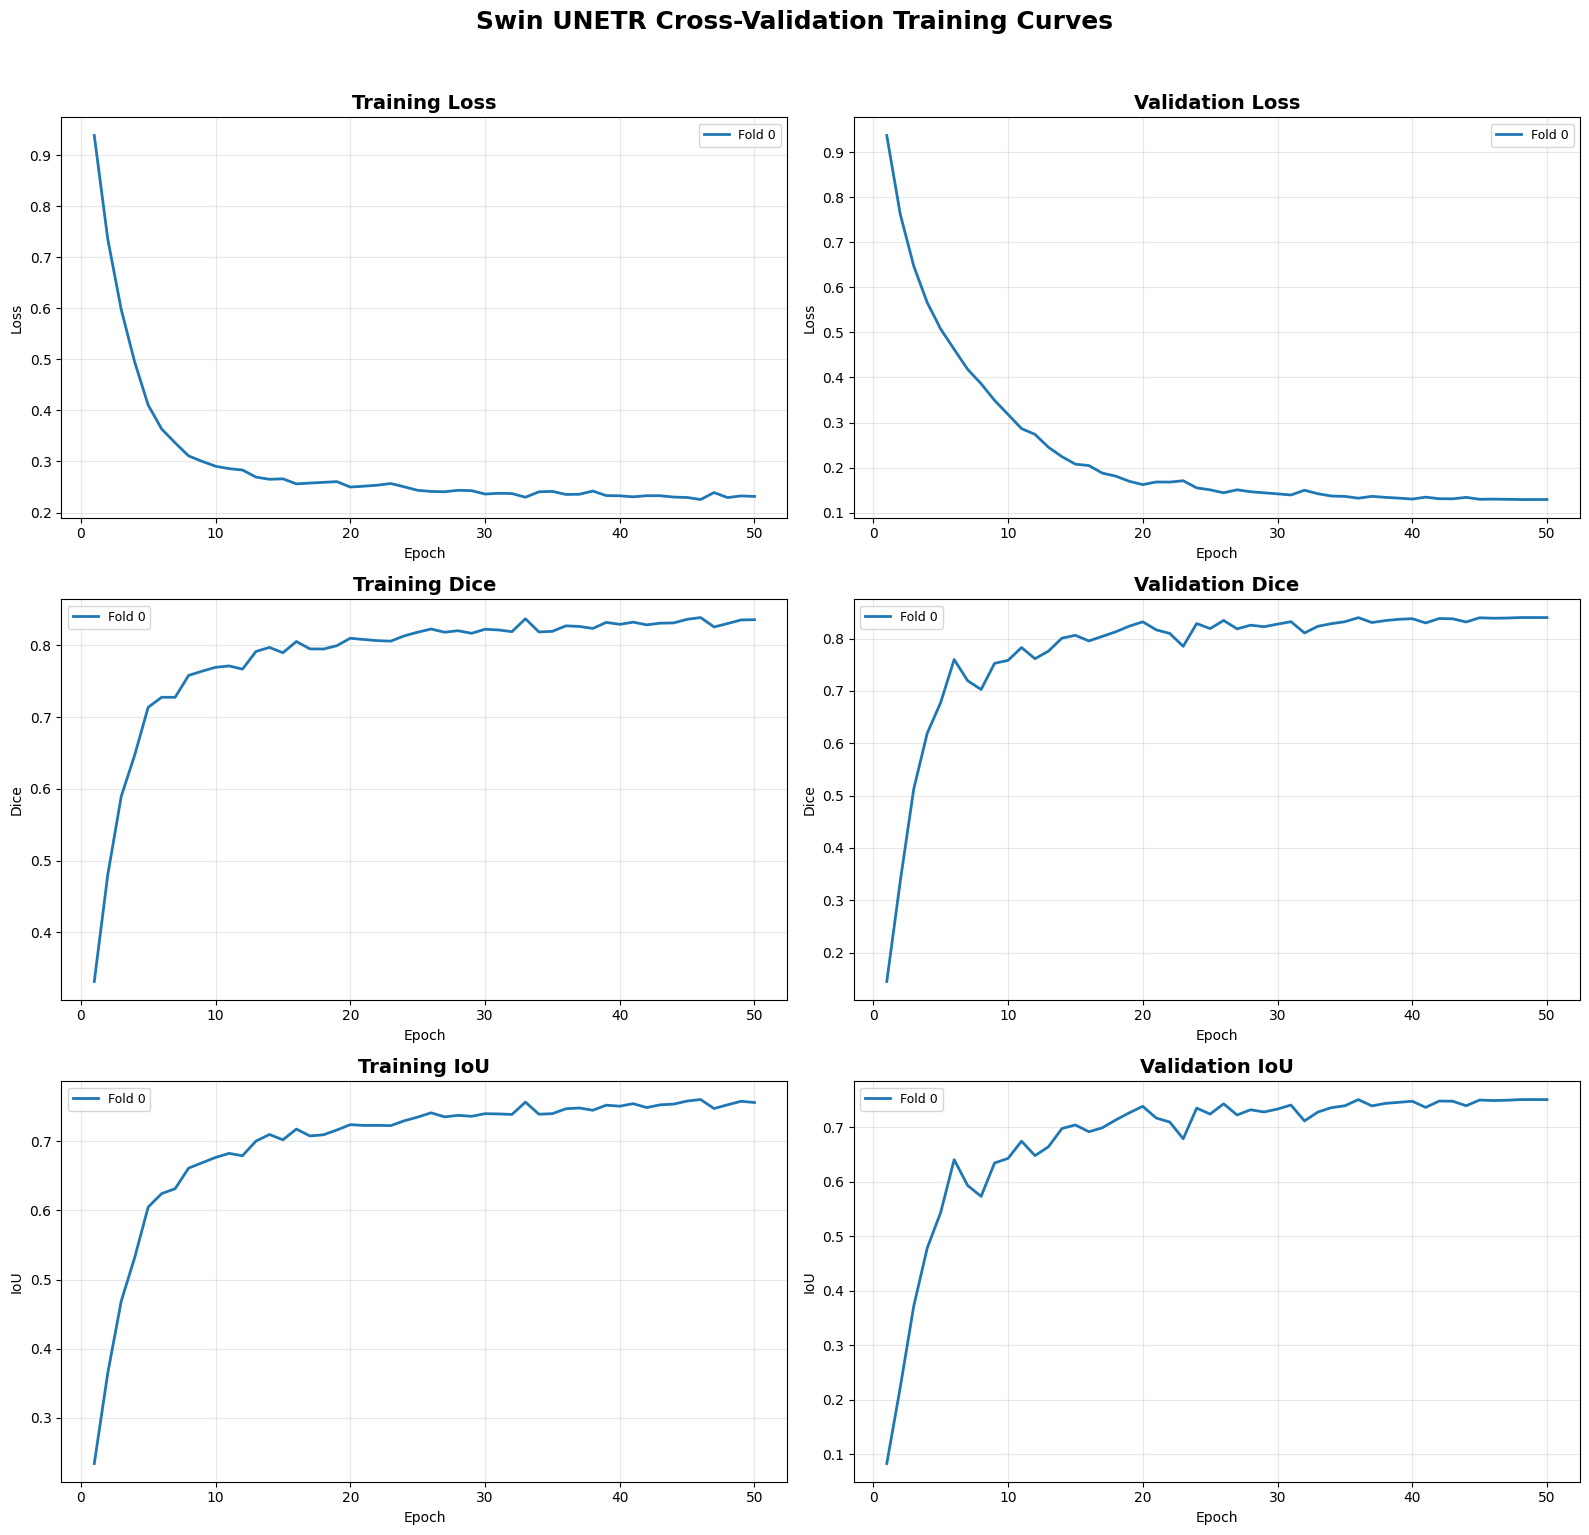

Training curves saved to: /kaggle/working/glioma_swin_unetr_fs12/results/5fold_training_curves.png


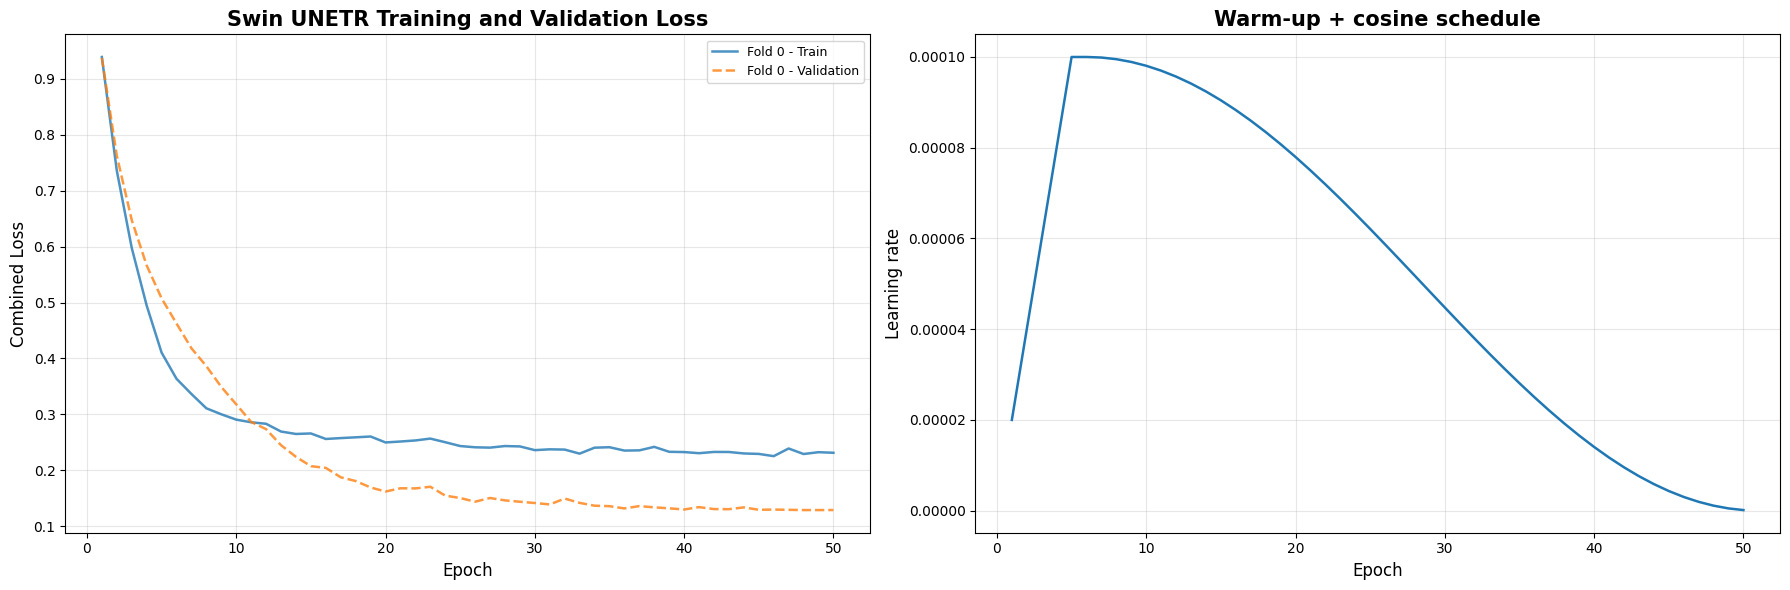

Loss curves saved to: /kaggle/working/glioma_swin_unetr_fs12/results/5fold_loss_curves.png


In [15]:
# ================================================================
# CELL 29 - TRAINING / VALIDATION CURVES
# ================================================================

available_folds = [
    fold for fold in range(N_FOLDS)
    if (RESULTS_DIR / f"fold_{fold}_history.csv").exists()
]

fig, axes = plt.subplots(
    3,
    2,
    figsize=(16, 15)
)

for fold in available_folds:

    history = pd.read_csv(
        RESULTS_DIR / f"fold_{fold}_history.csv"
    )

    for row, metric in enumerate(["loss", "dice", "iou"]):

        axes[row, 0].plot(
            history["epoch"],
            history[f"train_{metric}"],
            label=f"Fold {fold}",
            linewidth=2
        )

        axes[row, 1].plot(
            history["epoch"],
            history[f"val_{metric}"],
            label=f"Fold {fold}",
            linewidth=2
        )

titles = [
    ("Training Loss", "Validation Loss", "Loss"),
    ("Training Dice", "Validation Dice", "Dice"),
    ("Training IoU", "Validation IoU", "IoU")
]

for row, (left, right, ylabel) in enumerate(titles):

    axes[row, 0].set_title(left, fontsize=14, fontweight="bold")
    axes[row, 1].set_title(right, fontsize=14, fontweight="bold")

    axes[row, 0].set_ylabel(ylabel)
    axes[row, 1].set_ylabel(ylabel)

for ax in axes.flat:

    ax.set_xlabel("Epoch")
    ax.grid(True, alpha=0.3)
    ax.legend(fontsize=9)

plt.suptitle(
    "Swin UNETR Cross-Validation Training Curves",
    fontsize=18,
    fontweight="bold",
    y=1.02
)

plt.tight_layout()

curve_path = RESULTS_DIR / "5fold_training_curves.png"

plt.savefig(curve_path, dpi=200, bbox_inches="tight")

plt.show()

print(f"Training curves saved to: {curve_path}")

# ================================================================
# CELL 30 - LOSS CURVES AND LEARNING RATE
# ================================================================

fig, axes = plt.subplots(1, 2, figsize=(18, 6))

for fold in available_folds:

    history = pd.read_csv(
        RESULTS_DIR / f"fold_{fold}_history.csv"
    )

    axes[0].plot(
        history["epoch"],
        history["train_loss"],
        linestyle="-",
        linewidth=1.8,
        alpha=0.8,
        label=f"Fold {fold} - Train"
    )

    axes[0].plot(
        history["epoch"],
        history["val_loss"],
        linestyle="--",
        linewidth=1.8,
        alpha=0.8,
        label=f"Fold {fold} - Validation"
    )

    axes[1].plot(
        history["epoch"],
        history["learning_rate"],
        linewidth=1.8,
        label=f"Fold {fold}"
    )

axes[0].set_xlabel("Epoch", fontsize=12)
axes[0].set_ylabel("Combined Loss", fontsize=12)
axes[0].set_title("Swin UNETR Training and Validation Loss", fontsize=15, fontweight="bold")
axes[0].grid(True, alpha=0.3)
axes[0].legend(fontsize=9)

axes[1].set_xlabel("Epoch", fontsize=12)
axes[1].set_ylabel("Learning rate", fontsize=12)
axes[1].set_title("Warm-up + cosine schedule", fontsize=15, fontweight="bold")
axes[1].grid(True, alpha=0.3)

plt.tight_layout()

loss_curve_path = RESULTS_DIR / "5fold_loss_curves.png"

plt.savefig(loss_curve_path, dpi=200, bbox_inches="tight")

plt.show()

print(f"Loss curves saved to: {loss_curve_path}")


In [16]:
# ================================================================
# CELL 31 - PREDICTION VISUALIZATION
# ================================================================

SEG_CMAP = ListedColormap([
    (0, 0, 0, 0),       # background
    (1, 0, 0, 0.65),    # necrotic
    (0, 1, 0, 0.65),    # FLAIR hyperintensity
    (1, 1, 0, 0.65)     # enhancing
])


def visualize_prediction(
    model,
    dataframe,
    patient_index=0,
    slice_index=None,
    load_fn=load_patient_volumes
):
    """
    Shows FLAIR, ground truth and prediction on the axial slice
    with the largest tumor area (original image, true mask, predicted mask).
    """

    row = dataframe.iloc[patient_index]

    image, mask, _ = load_fn(row)

    images = torch.from_numpy(image).unsqueeze(0).to(DEVICE)

    model.eval()

    with torch.no_grad():
        with torch.cuda.amp.autocast(enabled=torch.cuda.is_available()):
            logits = predict_logits(model, images).float()

    prediction = torch.argmax(logits, dim=1)[0].cpu().numpy()

    if slice_index is None:
        slice_index = int(np.argmax((mask > 0).sum(axis=(0, 1))))

    dice_values = dice_score_per_class(
        torch.from_numpy(prediction)[None],
        torch.from_numpy(mask.astype(np.int64))[None]
    )

    flair = np.rot90(image[0, :, :, slice_index])

    fig, axes = plt.subplots(1, 3, figsize=(18, 6))

    axes[0].imshow(flair, cmap="gray")
    axes[0].set_title("FLAIR", fontsize=12, fontweight="bold")

    axes[1].imshow(flair, cmap="gray")
    axes[1].imshow(np.rot90(mask[:, :, slice_index]), cmap=SEG_CMAP,
                   vmin=0, vmax=3, interpolation="nearest")
    axes[1].set_title("Ground truth", fontsize=12, fontweight="bold")

    axes[2].imshow(flair, cmap="gray")
    axes[2].imshow(np.rot90(prediction[:, :, slice_index]), cmap=SEG_CMAP,
                   vmin=0, vmax=3, interpolation="nearest")
    axes[2].set_title("Swin UNETR prediction", fontsize=12, fontweight="bold")

    for ax in axes:
        ax.axis("off")

    plt.suptitle(
        f"Patient {row['patient_folder']} | slice {slice_index} | "
        f"Dice NCR {dice_values[0]:.2f} - FLAIR {dice_values[1]:.2f} - ET {dice_values[2]:.2f}",
        fontsize=14,
        fontweight="bold"
    )

    plt.tight_layout()
    plt.show()


print("Prediction visualization function defined.")


Prediction visualization function defined.


Loaded checkpoint from fold 0 (epoch 48, val loss 0.1291)


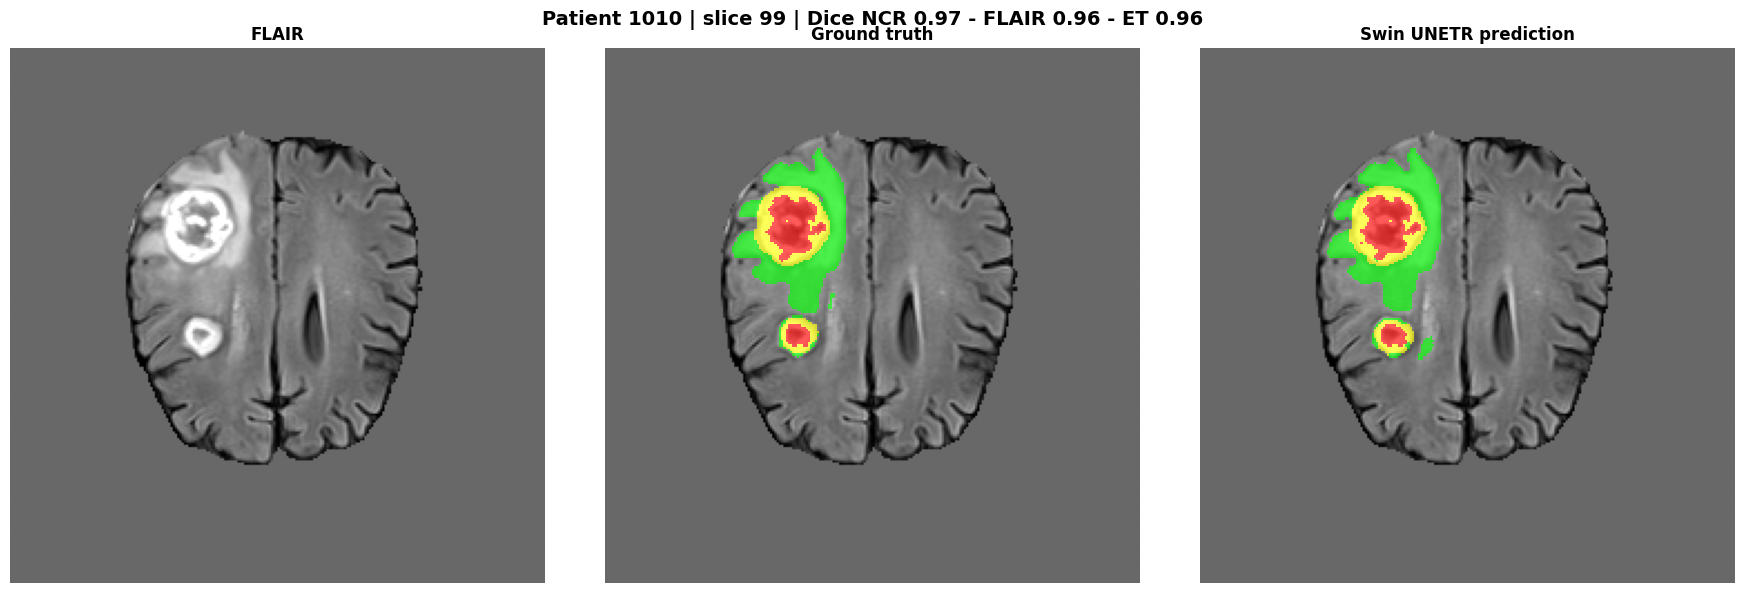

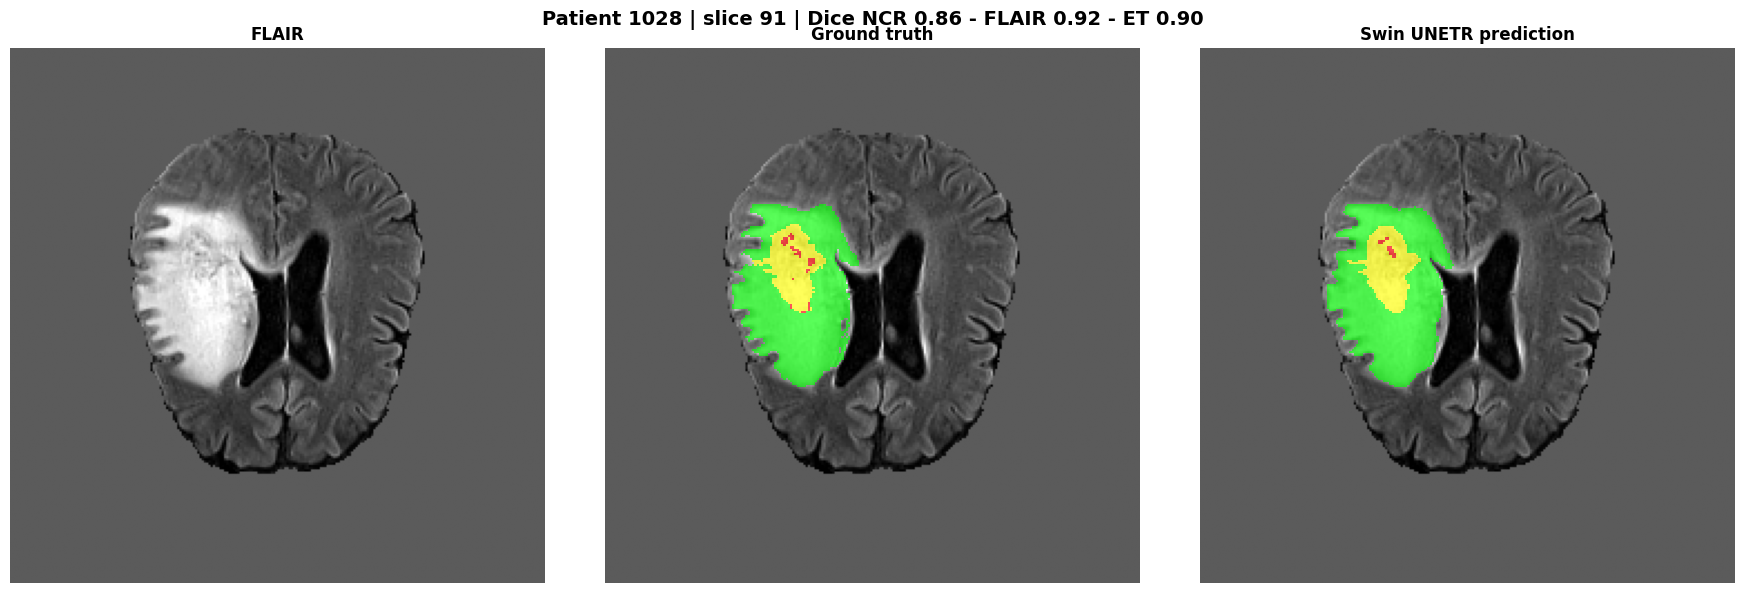

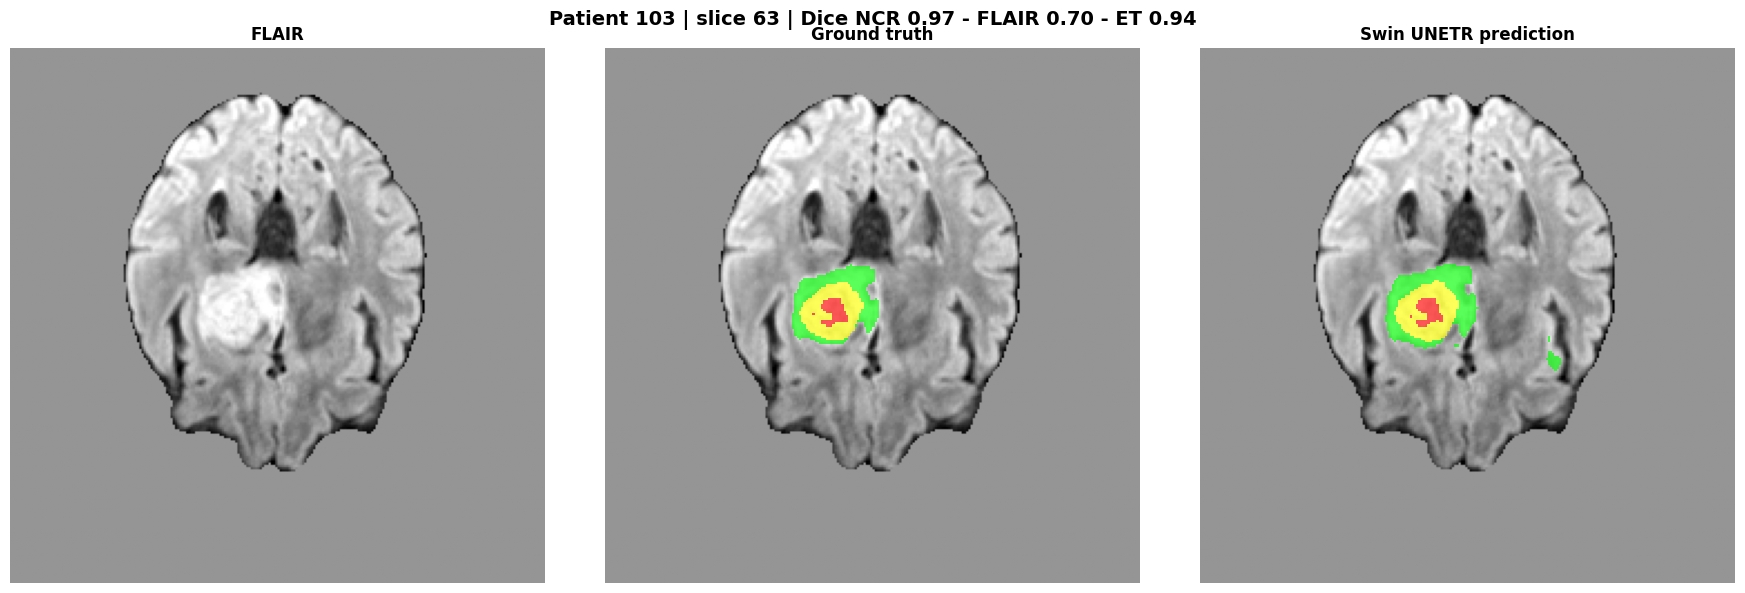

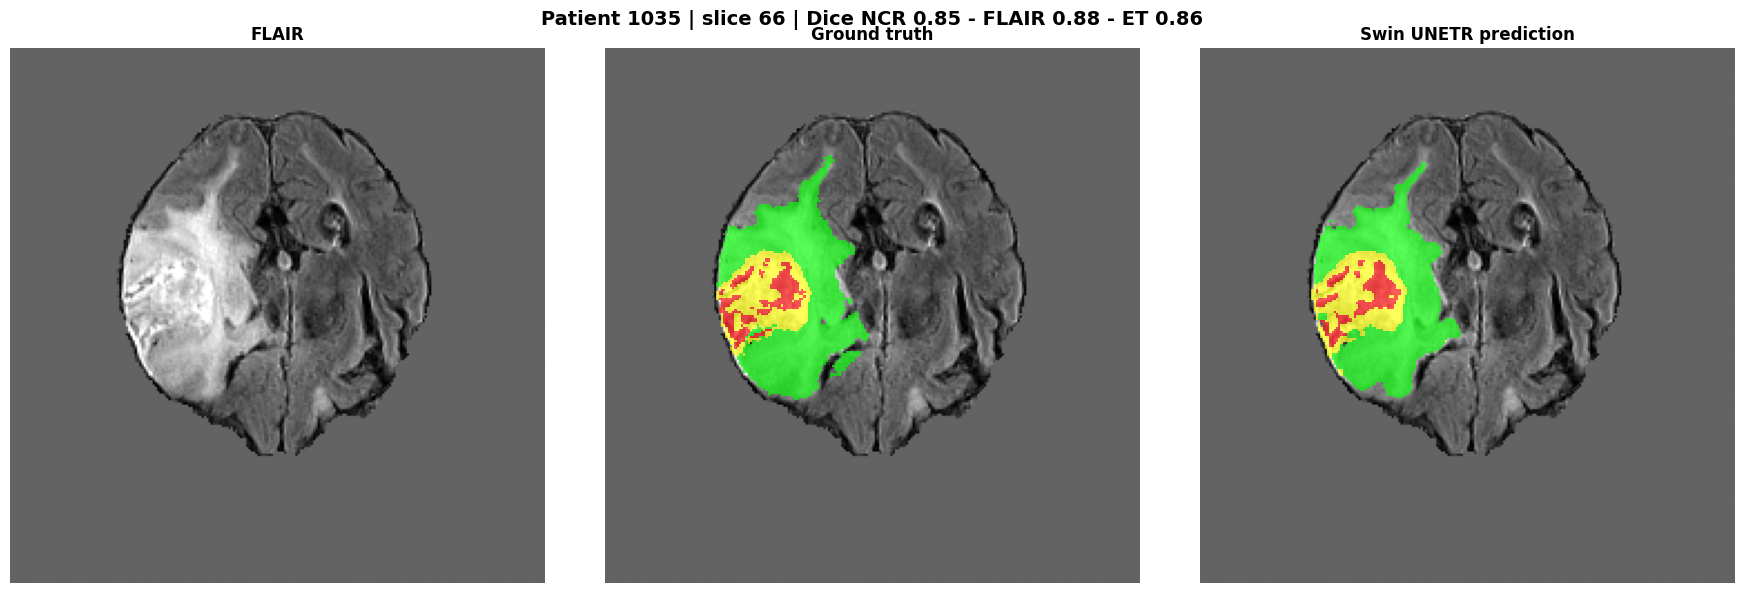

In [17]:
# ================================================================
# CELL 32 - LOAD BEST CHECKPOINT AND VISUALIZE
# ================================================================

FOLD_TO_VISUALIZE = FOLDS_TO_RUN[0]
N_PATIENTS_TO_SHOW = 4

best_path = CHECKPOINT_DIR / f"swin_unetr_fold{FOLD_TO_VISUALIZE}_best.pth"

if best_path.exists():

    visualization_model, checkpoint = load_model_from_checkpoint(best_path)

    _, fold_val_df = get_fold_split(FOLD_TO_VISUALIZE)

    print(
        f"Loaded checkpoint from fold {FOLD_TO_VISUALIZE} "
        f"(epoch {checkpoint['epoch']}, val loss {checkpoint['best_val_loss']:.4f})"
    )

    for patient_index in range(min(N_PATIENTS_TO_SHOW, len(fold_val_df))):

        visualize_prediction(
            visualization_model,
            fold_val_df,
            patient_index=patient_index,
            load_fn=load_cached_full_volume
        )

    del visualization_model
    gc.collect()

    if torch.cuda.is_available():
        torch.cuda.empty_cache()

else:
    print(f"No checkpoint yet for fold {FOLD_TO_VISUALIZE}.")


## 7. Full evaluation (Dice, IoU, HD, HD95 for whole tumor and sub-regions)

In [18]:
# ================================================================
# CELL 33 - FULL EVALUATION: Dice, IoU, HD, HD95 PER REGION
# ================================================================
#
# Objective 1a: whole tumor (labels 1 + 2 + 3)
# Objective 1b: necrotic core (1), FLAIR hyperintensity (2), enhancing tumor (3)
#
# Conventions (BraTS):
#   region empty in prediction AND ground truth -> Dice = IoU = 1, HD = HD95 = 0
#   region empty in only one of the two          -> Dice = IoU = 0, HD = HD95 = 373.13 mm
#
# evaluate_patients() takes a generic predict_fn(images) -> logits and a
# load_fn(row) -> (image, mask, _), so this cell can be copied into the
# 3D U-Net notebook (predict_fn = lambda x: model(x), load_fn = load_patient_volumes)
# to evaluate both models in exactly the same way.

EVAL_REGIONS = {
    "Whole tumor": [1, 2, 3],
    "Necrotic core": [1],
    "FLAIR hyperintensity": [2],
    "Enhancing tumor": [3]
}

SPACING_MM = (1.0, 1.0, 1.0)
HD_MAX_MM = float(np.sqrt(240 ** 2 + 240 ** 2 + 155 ** 2))   # 373.13 mm

RUN_FULL_EVALUATION = True   # out-of-fold validation metrics (each development patient once)
EVALUATE_TEST = False        # internal test set: only for the final model comparison


def surface(binary):
    return binary ^ binary_erosion(binary, structure=np.ones((3, 3, 3)), border_value=0)


def hausdorff_distances(pred, target):
    """HD and HD95 (mm): max of the two directed surface distances."""

    if not pred.any() and not target.any():
        return 0.0, 0.0

    if not pred.any() or not target.any():
        return HD_MAX_MM, HD_MAX_MM

    # Restrict to the bounding box of both objects (same distances, faster)
    coords = np.argwhere(pred | target)
    low = np.maximum(coords.min(axis=0) - 2, 0)
    high = coords.max(axis=0) + 3
    box = tuple(slice(a, b) for a, b in zip(low, high))
    pred, target = pred[box], target[box]

    pred_surface, target_surface = surface(pred), surface(target)

    d_pred_to_target = distance_transform_edt(~target_surface, sampling=SPACING_MM)[pred_surface]
    d_target_to_pred = distance_transform_edt(~pred_surface, sampling=SPACING_MM)[target_surface]

    hd = max(d_pred_to_target.max(), d_target_to_pred.max())
    hd95 = max(np.percentile(d_pred_to_target, 95), np.percentile(d_target_to_pred, 95))

    return float(hd), float(hd95)


def region_metrics(prediction, target):

    rows = []

    for region, labels in EVAL_REGIONS.items():

        p = np.isin(prediction, labels)
        t = np.isin(target, labels)

        p_sum, t_sum = int(p.sum()), int(t.sum())
        intersection = int(np.logical_and(p, t).sum())

        if p_sum + t_sum == 0:
            dice, iou = 1.0, 1.0
        else:
            dice = 2 * intersection / (p_sum + t_sum)
            iou = intersection / (p_sum + t_sum - intersection)

        hd, hd95 = hausdorff_distances(p, t)

        rows.append({
            "region": region,
            "Dice": dice,
            "IoU": iou,
            "HD_mm": hd,
            "HD95_mm": hd95,
            "gt_empty": t_sum == 0,
            "pred_empty": p_sum == 0
        })

    return rows


def evaluate_patients(predict_fn, dataframe, description="evaluation",
                      load_fn=load_patient_volumes, group_size=1):
    """
    Per-patient metrics on full volumes for every region.
    group_size > 1 predicts that many patients per call (one per GPU with
    VALIDATION_PREDICTOR.predict); the metrics are still computed per patient.
    """

    records = []

    starts = list(range(0, len(dataframe), group_size))

    for group_index, start in enumerate(tqdm(starts, desc=description)):

        rows = [dataframe.iloc[i] for i in range(start, min(start + group_size, len(dataframe)))]
        loaded = [load_fn(row) for row in rows]

        images = [torch.from_numpy(image) for image, _, _ in loaded]

        # Volumes of equal size are predicted together, otherwise one at a time
        if len({tuple(x.shape) for x in images}) == 1:
            batches = [torch.stack(images)]
        else:
            batches = [x.unsqueeze(0) for x in images]

        predictions = []

        for batch_images in batches:

            with torch.no_grad():
                with torch.cuda.amp.autocast(enabled=torch.cuda.is_available()):
                    logits = predict_fn(batch_images.to(DEVICE)).float()

            predictions.extend(torch.argmax(logits, dim=1).cpu().numpy())

            del logits

        for row, (_, mask, _), prediction in zip(rows, loaded, predictions):
            for metrics in region_metrics(prediction, mask):
                records.append({"patient_folder": row["patient_folder"], **metrics})

        del images, batches, loaded, predictions

        if (group_index + 1) % max(1, 10 // group_size) == 0:
            release_cpu_memory()

    return pd.DataFrame(records)


def summarize_metrics(results):

    return (
        results
        .groupby("region", sort=False)[["Dice", "IoU", "HD_mm", "HD95_mm"]]
        .agg(["mean", "std", "median"])
        .round(4)
    )


# ---------------------------------------------------------------
# Out-of-fold validation: each fold model on its own validation patients
# ---------------------------------------------------------------
folds_to_evaluate = [
    fold for fold in FOLDS_TO_RUN
    if fold_completed.get(fold, False)
    and (CHECKPOINT_DIR / f"swin_unetr_fold{fold}_best.pth").exists()
]

if RUN_FULL_EVALUATION and not folds_to_evaluate:
    print("No completed fold to evaluate in this session.")

elif RUN_FULL_EVALUATION and hours_used() > EVALUATION_DEADLINE_HOURS:
    print(
        f"Session time used {hours_used():.2f} h > {EVALUATION_DEADLINE_HOURS} h: "
        "full evaluation skipped. Run it in the next session with RESUME_FROM "
        "(completed folds are not retrained)."
    )

elif RUN_FULL_EVALUATION:

    oof_results = []

    for fold in folds_to_evaluate:

        fold_model, _ = load_model_from_checkpoint(
            CHECKPOINT_DIR / f"swin_unetr_fold{fold}_best.pth"
        )

        _, fold_val_df = get_fold_split(fold)

        # Fold model on every validation GPU, one patient per GPU
        VALIDATION_PREDICTOR.sync(fold_model)

        fold_results = evaluate_patients(
            VALIDATION_PREDICTOR.predict,
            fold_val_df,
            description=f"Fold {fold} validation",
            load_fn=load_cached_full_volume,
            group_size=len(VALIDATION_PREDICTOR.devices)
        )

        VALIDATION_PREDICTOR.models[0] = None

        fold_results["fold"] = fold
        oof_results.append(fold_results)

        del fold_model
        release_cpu_memory()
        if torch.cuda.is_available():
            torch.cuda.empty_cache()

    oof_results = pd.concat(oof_results, ignore_index=True)
    oof_results.to_csv(RESULTS_DIR / "validation_metrics_per_patient.csv", index=False)

    validation_summary = summarize_metrics(oof_results)
    validation_summary.to_csv(RESULTS_DIR / "validation_metrics_summary.csv")

    print("\nSWIN UNETR - CROSS-VALIDATION (out-of-fold) METRICS")
    display(validation_summary)

    print("\nMean Dice per fold and region:")
    display(oof_results.groupby(["fold", "region"], sort=False)["Dice"].mean().unstack().round(4))


# ---------------------------------------------------------------
# Internal test set: ensemble of the fold models (softmax average)
# ---------------------------------------------------------------
if EVALUATE_TEST and folds_to_evaluate:

    test_models = [
        load_model_from_checkpoint(CHECKPOINT_DIR / f"swin_unetr_fold{fold}_best.pth")[0]
        for fold in folds_to_evaluate
    ]

    def ensemble_predict(images):
        probabilities = torch.stack([
            torch.softmax(predict_logits(m, images).float(), dim=1)
            for m in test_models
        ]).mean(dim=0)
        return torch.log(probabilities.clamp_min(1e-8))

    test_results = evaluate_patients(ensemble_predict, test_df, description="Test set")
    test_results.to_csv(RESULTS_DIR / "test_metrics_per_patient.csv", index=False)

    test_summary = summarize_metrics(test_results)
    test_summary.to_csv(RESULTS_DIR / "test_metrics_summary.csv")

    print(f"\nSWIN UNETR - INTERNAL TEST SET ({len(test_df)} patients, ensemble of {len(test_models)} folds)")
    display(test_summary)


Fold 0 validation:   0%|          | 0/101 [00:00<?, ?it/s]


SWIN UNETR - CROSS-VALIDATION (out-of-fold) METRICS


Dice                     IoU                    HD_mm  \
                        mean     std  median    mean     std  median     mean   
region                                                                          
Whole tumor           0.8845  0.1318  0.9343  0.8125  0.1689  0.8767  69.3478   
Necrotic core         0.7574  0.2934  0.8925  0.6799  0.3041  0.8058  38.8316   
FLAIR hyperintensity  0.8073  0.1800  0.8779  0.7079  0.2106  0.7823  66.8444   
Enhancing tumor       0.8484  0.1966  0.9194  0.7729  0.2168  0.8509  57.6943   

                                        HD95_mm                    
                          std   median     mean      std   median  
region                                                             
Whole tumor           20.5323  69.3830  29.1573  29.0170  19.3391  
Necrotic core         69.6780  11.4455  25.0914  69.9675   3.0000  
FLAIR hyperintensity  22.6010  68.6076  26.4111  28.7979   9.4868  
Enhancing tumor       56.3771  53.4228  18.1503  55.3392   1.4142


Mean Dice per fold and region:


region,Whole tumor,Necrotic core,FLAIR hyperintensity,Enhancing tumor
fold,,,,
0,0.8845,0.7574,0.8073,0.8484


In [19]:
# Zip of the results folder (to download it in one click)
archive = shutil.make_archive(str(Path("/kaggle/working") / "swin_results"), "zip",
                              root_dir=OUTPUT_DIR, base_dir="results")
print("Results archive:", archive)

Results archive: /kaggle/working/swin_results.zip
